# **Deep Learning - Comparative of Generative Model**

> Michael Ahlovely Stevenson

In [ ]:
!pip install -q torchmetrics[image] pytorch-fid scikit-image

In [ ]:
import os
import time
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader, ConcatDataset, random_split
import torchvision
import torchvision.transforms as transforms
from torchvision.utils import make_grid

# Configure GPU/CPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Perangkat aktif: {device}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")

SEED = 42

def set_seed(seed: int = 42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    os.environ["PYTHONHASHSEED"] = str(seed)

set_seed(SEED)

# Hyperparameter Global
CONFIG = {
    "seed": SEED,
    "dataset_name": "Fashion-MNIST",
    "img_size": 28,
    "channels": 1,
    "input_dim": 28 * 28, # 784 px (untuk MLP, AE, Sparse AE, VAE, Vanilla GAN)
    "num_classes": 10,
    "batch_size": 128,
    "latent_dim": 64,
    "noise_dim": 100,
    "eval_batch_size": 64,
    "num_workers": 2
}

# Label Fashion-MNIST
CLASS_NAMES = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"
]

# Direktori
os.makedirs("checkpoints", exist_ok=True)
os.makedirs("figures", exist_ok=True)

Perangkat aktif: cuda
GPU: Tesla T4


## **1. Data Pipeline & Preprocessing**

In [ ]:
base_transform = transforms.Compose([
    transforms.ToTensor()
])

train_raw = torchvision.datasets.FashionMNIST(
    root="./data", train=True, download=True, transform=base_transform
)
test_raw = torchvision.datasets.FashionMNIST(
    root="./data", train=False, download=True, transform=base_transform
)

# Dataset Split 80% : 10% : 10%
full_dataset = ConcatDataset([train_raw, test_raw])
total_samples = len(full_dataset)

train_size = int(0.8 * total_samples)
val_size = int(0.1 * total_samples)
test_size = total_samples - train_size - val_size

split_generator = torch.Generator().manual_seed(CONFIG["seed"])
train_dataset, val_dataset, test_dataset = random_split(
    full_dataset,
    [train_size, val_size, test_size],
    generator=split_generator
)

def seed_worker(worker_id):
    worker_seed = torch.initial_seed() % 2**32
    np.random.seed(worker_seed)
    random.seed(worker_seed)

loader_generator = torch.Generator().manual_seed(CONFIG["seed"])

# DataLoader
train_loader = DataLoader(
    train_dataset,
    batch_size=CONFIG["batch_size"],
    shuffle=True,
    num_workers=CONFIG["num_workers"],
    pin_memory=True,
    worker_init_fn=seed_worker,
    generator=loader_generator
)

val_loader = DataLoader(
    val_dataset,
    batch_size=CONFIG["batch_size"],
    shuffle=False,
    num_workers=CONFIG["num_workers"],
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=CONFIG["batch_size"],
    shuffle=False,
    num_workers=CONFIG["num_workers"],
    pin_memory=True
)

def scale_to_minus_one_one(x: torch.Tensor) -> torch.Tensor:
    """ [0, 1] -> [-1, 1] untuk GAN dan DDPM."""
    return x * 2.0 - 1.0

def scale_to_zero_one(x: torch.Tensor) -> torch.Tensor:
    """ [-1, 1] -> [0, 1] untuk evaluasi & visualisasi."""
    return torch.clamp((x + 1.0) / 2.0, 0.0, 1.0)

100%|██████████| 26.4M/26.4M [00:02<00:00, 12.6MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 199kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.38MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 3.29MB/s]


=== SUMMARY DATASET & DATALOADER ===
Total Dataset : 70,000 citra
Train Set     : 56,000 citra (438 batches)
Validation Set: 7,000 citra (55 batches)
Test Set      : 7,000 citra (55 batches)

Dimensi Batch Tensor : torch.Size([128, 1, 28, 28])
Rentang Nilai Piksel : [0.00, 1.00]


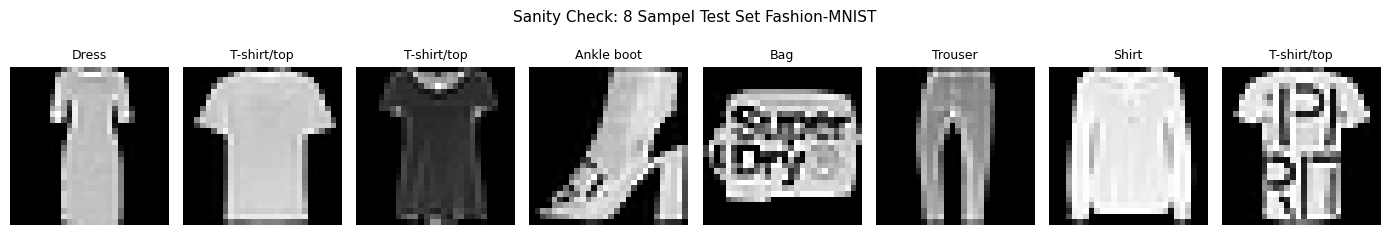

In [ ]:
print("=== SUMMARY DATASET & DATALOADER ===")
print(f"Total Dataset : {total_samples:,} citra")
print(f"Train Set     : {len(train_dataset):,} citra ({len(train_loader)} batches)")
print(f"Validation Set: {len(val_dataset):,} citra ({len(val_loader)} batches)")
print(f"Test Set      : {len(test_dataset):,} citra ({len(test_loader)} batches)")

# Sample: 1 batch dari test_loader
sample_images, sample_labels = next(iter(test_loader))
print(f"\nDimensi Batch Tensor : {sample_images.shape}")
print(f"Rentang Nilai Piksel : [{sample_images.min():.2f}, {sample_images.max():.2f}]")

# 8 sampel pertama dari Test Set
fig, axes = plt.subplots(1, 8, figsize=(14, 2.2))
for i in range(8):
    axes[i].imshow(sample_images[i].squeeze().numpy(), cmap="gray")
    axes[i].set_title(CLASS_NAMES[sample_labels[i].item()], fontsize=9)
    axes[i].axis("off")

plt.suptitle("Sanity Check: 8 Sampel Test Set Fashion-MNIST", fontsize=11, y=1.05)
plt.tight_layout()
plt.show()

## **2. Eksperimen MLP Classifier**

### **2.1. Train MCP Classifier**

In [ ]:
set_seed(SEED)

class MLPClassifier(nn.Module):
    def __init__(self, input_dim: int = 784, latent_dim: int = 64, num_classes: int = 10):
        super().__init__()
        self.fc1 = nn.Linear(input_dim, 256)
        self.fc2 = nn.Linear(256, latent_dim)
        self.fc3 = nn.Linear(latent_dim, num_classes)

    def extract_latent(self, x: torch.Tensor) -> torch.Tensor:
        x_flat = x.view(x.size(0), -1)
        h1 = F.relu(self.fc1(x_flat))
        z_mlp = F.relu(self.fc2(h1))
        return z_mlp

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        z_mlp = self.extract_latent(x)
        logits = self.fc3(z_mlp)
        return logits

mlp_classifier = MLPClassifier(
    input_dim=CONFIG["input_dim"],
    latent_dim=CONFIG["latent_dim"],
    num_classes=CONFIG["num_classes"]
).to(device)

criterion_cls = nn.CrossEntropyLoss()
optimizer_cls = optim.Adam(mlp_classifier.parameters(), lr=1e-3)

EPOCHS_MLP = 20
best_val_acc = 0.0

print("=== TRAINING MLP CLASSIFIER ===")
for epoch in range(1, EPOCHS_MLP + 1):
    mlp_classifier.train()
    train_loss, correct_train, total_train = 0.0, 0, 0

    for imgs, labels in train_loader:
        imgs, labels = imgs.to(device), labels.to(device)
        optimizer_cls.zero_grad()
        outputs = mlp_classifier(imgs)
        loss = criterion_cls(outputs, labels)
        loss.backward()
        optimizer_cls.step()

        train_loss += loss.item() * imgs.size(0)
        _, predicted = outputs.max(1)
        total_train += labels.size(0)
        correct_train += predicted.eq(labels).sum().item()

    # Evaluasi pada Validation Set
    mlp_classifier.eval()
    correct_val, total_val = 0, 0
    with torch.no_grad():
        for imgs, labels in val_loader:
            imgs, labels = imgs.to(device), labels.to(device)
            outputs = mlp_classifier(imgs)
            _, predicted = outputs.max(1)
            total_val += labels.size(0)
            correct_val += predicted.eq(labels).sum().item()

    val_acc = 100.0 * correct_val / total_val
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(mlp_classifier.state_dict(), "checkpoints/mlp_classifier_best.pth")

    if epoch % 5 == 0 or epoch == 1:
        print(f"Epoch [{epoch:02d}/{EPOCHS_MLP}] | "
              f"Train Loss: {train_loss/total_train:.4f} | "
              f"Train Acc: {100.0*correct_train/total_train:.2f}% | "
              f"Val Acc: {val_acc:.2f}%")

# Muat bobot terbaik dan evaluasi pada Test Set
mlp_classifier.load_state_dict(torch.load("checkpoints/mlp_classifier_best.pth"))
mlp_classifier.eval()

correct_test, total_test = 0, 0
all_z_test, all_imgs_test, all_labels_test = [], [], []

with torch.no_grad():
    for imgs, labels in test_loader:
        imgs, labels = imgs.to(device), labels.to(device)
        z_batch = mlp_classifier.extract_latent(imgs)
        logits = mlp_classifier.fc3(z_batch)
        _, predicted = logits.max(1)

        total_test += labels.size(0)
        correct_test += predicted.eq(labels).sum().item()

        all_z_test.append(z_batch.cpu())
        all_imgs_test.append(imgs.cpu())
        all_labels_test.append(labels.cpu())

test_acc = 100.0 * correct_test / total_test
Z_mlp_test = torch.cat(all_z_test, dim=0)
X_test_tensor = torch.cat(all_imgs_test, dim=0)
Y_test_tensor = torch.cat(all_labels_test, dim=0)

print(f"\nAkurasi Test Set MLP Classifier: {test_acc:.2f}% (Target minimal: 88.00%)")
assert test_acc >= 88.0, "Akurasi belum mencapai 88%, tambah jumlah epoch pelatihan."

# Ekstraksi matriks bobot terlatih W1 (256x784), W2 (64x256), W3 (10x64)
W1 = mlp_classifier.fc1.weight.detach()
W2 = mlp_classifier.fc2.weight.detach()
W3 = mlp_classifier.fc3.weight.detach()
print(f"Dimensi Matriks Bobot -> W1: {tuple(W1.shape)}, W2: {tuple(W2.shape)}, W3: {tuple(W3.shape)}")

=== TRAINING MLP CLASSIFIER ===
Epoch [01/20] | Train Loss: 0.5937 | Train Acc: 79.24% | Val Acc: 83.20%
Epoch [05/20] | Train Loss: 0.3159 | Train Acc: 88.41% | Val Acc: 87.60%
Epoch [10/20] | Train Loss: 0.2554 | Train Acc: 90.48% | Val Acc: 88.60%
Epoch [15/20] | Train Loss: 0.2106 | Train Acc: 92.11% | Val Acc: 89.19%
Epoch [20/20] | Train Loss: 0.1830 | Train Acc: 93.04% | Val Acc: 88.50%

Akurasi Test Set MLP Classifier: 88.50% (Target minimal: 88.00%)
Dimensi Matriks Bobot -> W1: (256, 784), W2: (64, 256), W3: (10, 64)


## 2.2. **Top-Down Weight Transposition**

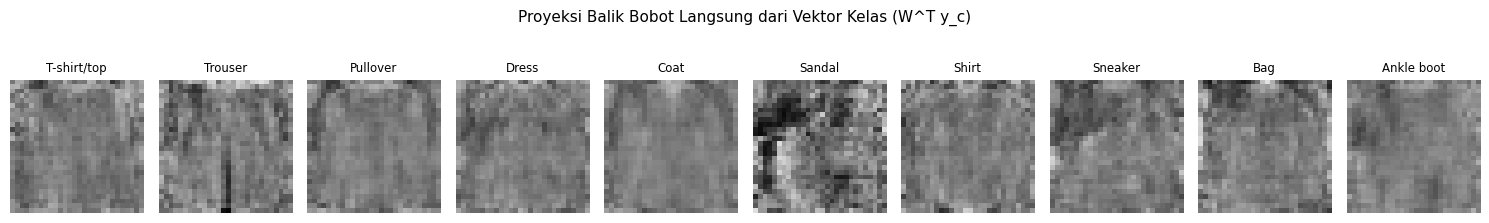

In [ ]:
with torch.no_grad():
    y_onehot = torch.eye(CONFIG["num_classes"], device=device)  # (10, 10)
    z_hat_cls = F.relu(torch.matmul(y_onehot, W3))              # (10, 64)
    h1_hat_cls = F.relu(torch.matmul(z_hat_cls, W2))            # (10, 256)
    x_hat_cls = torch.sigmoid(torch.matmul(h1_hat_cls, W1))     # (10, 784)
    x_hat_cls_imgs = x_hat_cls.view(-1, 1, 28, 28).cpu()

# Grid 1x10 -> 10 kelas Fashion-MNIST
fig, axes = plt.subplots(1, 10, figsize=(15, 2.2))
for c in range(10):
    axes[c].imshow(x_hat_cls_imgs[c].squeeze(), cmap="gray", vmin=0, vmax=1)
    axes[c].set_title(CLASS_NAMES[c], fontsize=8.5)
    axes[c].axis("off")

plt.suptitle("Proyeksi Balik Bobot Langsung dari Vektor Kelas (W^T y_c)", fontsize=11, y=1.05)
plt.tight_layout()
plt.show()

## **2.3. Latent Transpose Projection**

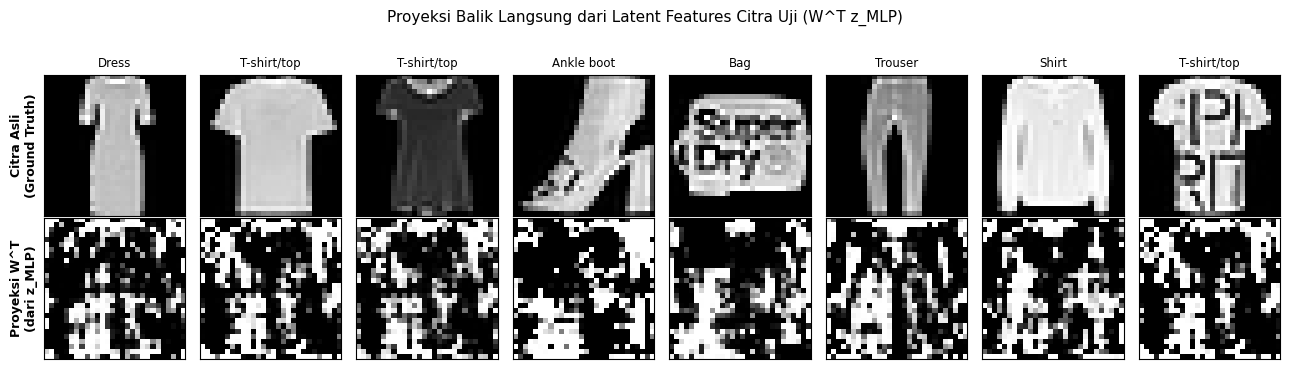

In [ ]:
with torch.no_grad():
    sample_x_real = X_test_tensor[:8].to(device)
    sample_z_mlp = Z_mlp_test[:8].to(device)
    sample_y_real = Y_test_tensor[:8]

    h1_hat_lat = F.relu(torch.matmul(sample_z_mlp, W2))         # (8, 256)
    x_hat_lat = torch.sigmoid(torch.matmul(h1_hat_lat, W1))     # (8, 784)
    x_hat_lat_imgs = x_hat_lat.view(-1, 1, 28, 28).cpu()

# Grid 2x8: Citra Asli vs Hasil Proyeksi W^T dari z_MLP
fig, axes = plt.subplots(2, 8, figsize=(13, 3.6))
for i in range(8):
    axes[0, i].imshow(sample_x_real[i].cpu().squeeze(), cmap="gray", vmin=0, vmax=1)
    axes[0, i].set_title(CLASS_NAMES[sample_y_real[i].item()], fontsize=8.5)
    axes[0, i].set_xticks([])
    axes[0, i].set_yticks([])

    axes[1, i].imshow(x_hat_lat_imgs[i].squeeze(), cmap="gray", vmin=0, vmax=1)
    axes[1, i].set_xticks([])
    axes[1, i].set_yticks([])

axes[0, 0].set_ylabel("Citra Asli\n(Ground Truth)", fontsize=9, fontweight="bold")
axes[1, 0].set_ylabel("Proyeksi W^T\n(dari z_MLP)", fontsize=9, fontweight="bold")

plt.suptitle("Proyeksi Balik Langsung dari Latent Features Citra Uji (W^T z_MLP)", fontsize=11, y=1.02)
plt.tight_layout()
plt.show()

## **2.4. Frozen Latent Decoding**

In [ ]:
from torchmetrics.image import PeakSignalNoiseRatio, StructuralSimilarityIndexMeasure

def evaluate_reconstruction_metrics(recon_fn, loader, device):
    psnr_metric = PeakSignalNoiseRatio(data_range=1.0).to(device)
    ssim_metric = StructuralSimilarityIndexMeasure(data_range=1.0).to(device)
    total_mse = 0.0
    total_samples = 0

    with torch.no_grad():
        for imgs, _ in loader:
            imgs = imgs.to(device)
            recons = recon_fn(imgs)
            mse_batch = F.mse_loss(recons, imgs, reduction="sum").item()
            total_mse += mse_batch
            total_samples += imgs.numel()

            psnr_metric.update(recons, imgs)
            ssim_metric.update(recons, imgs)

    mean_mse = total_mse / total_samples
    mean_psnr = psnr_metric.compute().item()
    mean_ssim = ssim_metric.compute().item()
    return mean_mse, mean_psnr, mean_ssim

# Freeze seluruh bobot MLP Classifier
for param in mlp_classifier.parameters():
    param.requires_grad = False
mlp_classifier.eval()

class FrozenLatentDecoder(nn.Module):
    def __init__(self, latent_dim: int = 64, output_dim: int = 784):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(latent_dim, 256),
            nn.ReLU(),
            nn.Linear(256, output_dim),
            nn.Sigmoid()
        )

    def forward(self, z: torch.Tensor) -> torch.Tensor:
        out = self.net(z)
        return out.view(-1, 1, 28, 28)

set_seed(SEED)
frozen_decoder = FrozenLatentDecoder(
    latent_dim=CONFIG["latent_dim"],
    output_dim=CONFIG["input_dim"]
).to(device)

optimizer_dec = optim.Adam(frozen_decoder.parameters(), lr=1e-3)
criterion_mse = nn.MSELoss()

EPOCHS_DEC = 20
print("=== TRAINING FROZEN LATENT DECODER ===")
for epoch in range(1, EPOCHS_DEC + 1):
    frozen_decoder.train()
    running_loss = 0.0

    for imgs, _ in train_loader:
        imgs = imgs.to(device)
        with torch.no_grad():
            z_frozen = mlp_classifier.extract_latent(imgs)

        optimizer_dec.zero_grad()
        x_recon = frozen_decoder(z_frozen)
        loss = criterion_mse(x_recon, imgs)
        loss.backward()
        optimizer_dec.step()

        running_loss += loss.item() * imgs.size(0)

    if epoch % 5 == 0 or epoch == 1:
        print(f"Epoch [{epoch:02d}/{EPOCHS_DEC}] | Train MSE Loss: {running_loss/len(train_dataset):.6f}")

# Evaluasi pada Test Set
frozen_decoder.eval()
mlp_mse, mlp_psnr, mlp_ssim = evaluate_reconstruction_metrics(
    lambda x: frozen_decoder(mlp_classifier.extract_latent(x)),
    test_loader,
    device
)

MLP_EVAL_METRICS = {
    "Model": "Frozen MLP Decoder (Z_MLP)",
    "Test MSE": mlp_mse,
    "Test PSNR (dB)": mlp_psnr,
    "Test SSIM": mlp_ssim
}

print("\n=== HASIL METRIK REKONSTRUKSI FROZEN LATENT DECODER (TEST SET) ===")
print(f"Test MSE  : {mlp_mse:.6f}")
print(f"Test PSNR : {mlp_psnr:.2f} dB")
print(f"Test SSIM : {mlp_ssim:.4f}")

=== TRAINING FROZEN LATENT DECODER ===
Epoch [01/20] | Train MSE Loss: 0.036876
Epoch [05/20] | Train MSE Loss: 0.020344
Epoch [10/20] | Train MSE Loss: 0.018433
Epoch [15/20] | Train MSE Loss: 0.017519
Epoch [20/20] | Train MSE Loss: 0.016993

=== HASIL METRIK REKONSTRUKSI FROZEN LATENT DECODER (TEST SET) ===
Test MSE  : 0.017486
Test PSNR : 17.57 dB
Test SSIM : 0.7087


## **2.5. Test Sampling Generatif**

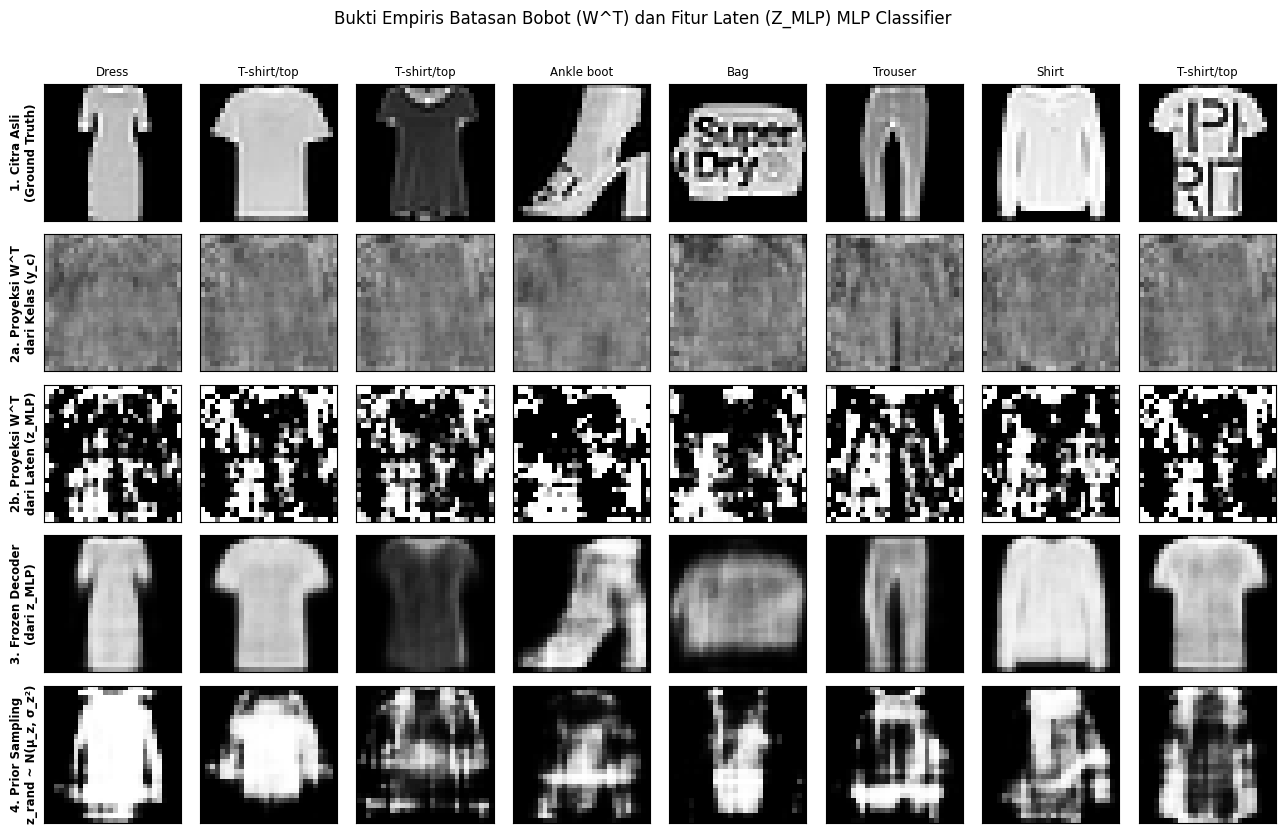

In [ ]:
set_seed(SEED)

mu_z = Z_mlp_test.mean(dim=0).to(device)       # (64,)
sigma_z = Z_mlp_test.std(dim=0).to(device)     # (64,)

eps = torch.randn(8, CONFIG["latent_dim"], device=device)
z_rand = mu_z + sigma_z * eps

with torch.no_grad():
    x_rand_mlp = frozen_decoder(z_rand).cpu()
    x_recon_frozen_sample = frozen_decoder(Z_mlp_test[:8].to(device)).cpu()

torch.save({
    "ground_truth": X_test_tensor[:8],
    "labels": sample_y_real,
    "w_transpose_class": x_hat_cls_imgs[sample_y_real],
    "w_transpose_latent": x_hat_lat_imgs,
    "frozen_mlp_recon": x_recon_frozen_sample,
    "mlp_prior_samples": x_rand_mlp,
    "metrics": MLP_EVAL_METRICS
}, "checkpoints/bagian2_mlp_artifacts.pt")

# Visualisasi 4 Panel Bukti Eksperimen MLP
fig, axes = plt.subplots(5, 8, figsize=(13, 8.2))
row_titles = [
    "1. Citra Asli\n(Ground Truth)",
    "2a. Proyeksi W^T\ndari Kelas (y_c)",
    "2b. Proyeksi W^T\ndari Laten (z_MLP)",
    "3. Frozen Decoder\n(dari z_MLP)",
    "4. Prior Sampling\nz_rand ~ N(μ_z, σ_z²)"
]

panels = [
    X_test_tensor[:8],
    x_hat_cls_imgs[sample_y_real],
    x_hat_lat_imgs,
    x_recon_frozen_sample,
    x_rand_mlp
]

for row_idx, (panel_imgs, title) in enumerate(zip(panels, row_titles)):
    for col_idx in range(8):
        axes[row_idx, col_idx].imshow(panel_imgs[col_idx].squeeze(), cmap="gray", vmin=0, vmax=1)
        axes[row_idx, col_idx].set_xticks([])
        axes[row_idx, col_idx].set_yticks([])
        if row_idx == 0:
            axes[row_idx, col_idx].set_title(CLASS_NAMES[sample_y_real[col_idx].item()], fontsize=8.5)
        if col_idx == 0:
            axes[row_idx, col_idx].set_ylabel(title, fontsize=8.5, fontweight="bold")

plt.suptitle("Bukti Empiris Batasan Bobot (W^T) dan Fitur Laten (Z_MLP) MLP Classifier", fontsize=12, y=1.01)
plt.tight_layout()
plt.savefig("figures/figur3_preliminary_mlp.png", dpi=300, bbox_inches="tight")
plt.show()

## **3. Arsitektur & Training Keluarga Autoencoder**

In [ ]:
# 1. Vanilla Autoencoder (Dimensi Laten = 64)
class VanillaAE(nn.Module):
    def __init__(self, input_dim: int = 784, latent_dim: int = 64):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(input_dim, 256),
            nn.ReLU(),
            nn.Linear(256, latent_dim),
            nn.ReLU()
        )
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 256),
            nn.ReLU(),
            nn.Linear(256, input_dim),
            nn.Sigmoid()
        )

    def encode(self, x: torch.Tensor) -> torch.Tensor:
        return self.encoder(x.view(x.size(0), -1))

    def decode(self, z: torch.Tensor) -> torch.Tensor:
        return self.decoder(z).view(-1, 1, 28, 28)

    def forward(self, x: torch.Tensor):
        z = self.encode(x)
        recon = self.decode(z)
        return recon, z


# 2. Sparse Autoencoder (Dimensi Laten Overcomplete = 256 + L1 Penalty)
class SparseAE(nn.Module):
    def __init__(self, input_dim: int = 784, sparse_dim: int = 256):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(input_dim, sparse_dim),
            nn.ReLU()
        )
        self.decoder = nn.Sequential(
            nn.Linear(sparse_dim, input_dim),
            nn.Sigmoid()
        )

    def encode(self, x: torch.Tensor) -> torch.Tensor:
        return self.encoder(x.view(x.size(0), -1))

    def decode(self, z: torch.Tensor) -> torch.Tensor:
        return self.decoder(z).view(-1, 1, 28, 28)

    def forward(self, x: torch.Tensor):
        z = self.encode(x)
        recon = self.decode(z)
        return recon, z


# 3. Variational Autoencoder / VAE (Dimensi Laten = 64)
class VariationalAE(nn.Module):
    def __init__(self, input_dim: int = 784, latent_dim: int = 64):
        super().__init__()
        self.fc_enc = nn.Sequential(
            nn.Linear(input_dim, 256),
            nn.ReLU()
        )
        self.fc_mu = nn.Linear(256, latent_dim)
        self.fc_logvar = nn.Linear(256, latent_dim)

        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 256),
            nn.ReLU(),
            nn.Linear(256, input_dim),
            nn.Sigmoid()
        )

    def encode(self, x: torch.Tensor):
        h = self.fc_enc(x.view(x.size(0), -1))
        mu = self.fc_mu(h)
        logvar = self.fc_logvar(h)
        return mu, logvar

    def reparameterize(self, mu: torch.Tensor, logvar: torch.Tensor) -> torch.Tensor:
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + eps * std

    def decode(self, z: torch.Tensor) -> torch.Tensor:
        return self.decoder(z).view(-1, 1, 28, 28)

    def forward(self, x: torch.Tensor):
        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar)
        recon = self.decode(z)
        return recon, mu, logvar


def vae_loss_function(recon_x: torch.Tensor, x: torch.Tensor, mu: torch.Tensor, logvar: torch.Tensor):
    batch_size = x.size(0)
    recon_loss = F.mse_loss(recon_x, x, reduction="sum") / batch_size
    kl_loss = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp()) / batch_size
    return recon_loss + kl_loss, recon_loss, kl_loss

In [ ]:
EPOCHS_AE = 25
SPARSITY_LAMBDA = 1e-3

HISTORY = {}
TRAIN_TIME_PER_EPOCH = {}

# --- A. Training VANILLA AUTOENCODER ---
set_seed(SEED)
vanilla_ae = VanillaAE(CONFIG["input_dim"], CONFIG["latent_dim"]).to(device)
opt_vae_plain = optim.Adam(vanilla_ae.parameters(), lr=1e-3)
HISTORY["Vanilla AE"] = []
epoch_times = []

print("=== MELATIH VANILLA AUTOENCODER ===")
for epoch in range(1, EPOCHS_AE + 1):
    t0 = time.time()
    vanilla_ae.train()
    running_loss = 0.0

    for imgs, _ in train_loader:
        imgs = imgs.to(device)
        opt_vae_plain.zero_grad()
        recon, _ = vanilla_ae(imgs)
        loss = F.mse_loss(recon, imgs)
        loss.backward()
        opt_vae_plain.step()
        running_loss += loss.item() * imgs.size(0)

    epoch_times.append(time.time() - t0)
    avg_loss = running_loss / len(train_dataset)
    HISTORY["Vanilla AE"].append(avg_loss)
    if epoch % 5 == 0 or epoch == 1:
        print(f"Epoch [{epoch:02d}/{EPOCHS_AE}] | Loss: {avg_loss:.6f} | Time: {epoch_times[-1]:.2f}s")

TRAIN_TIME_PER_EPOCH["Vanilla AE"] = float(np.mean(epoch_times))
torch.save(vanilla_ae.state_dict(), "checkpoints/vanilla_ae.pth")


# --- B. Training SPARSE AUTOENCODER ---
set_seed(SEED)
sparse_ae = SparseAE(CONFIG["input_dim"], sparse_dim=256).to(device)
opt_sae = optim.Adam(sparse_ae.parameters(), lr=1e-3)
HISTORY["Sparse AE"] = []
epoch_times = []

print("\n=== MELATIH SPARSE AUTOENCODER ===")
for epoch in range(1, EPOCHS_AE + 1):
    t0 = time.time()
    sparse_ae.train()
    running_loss = 0.0

    for imgs, _ in train_loader:
        imgs = imgs.to(device)
        opt_sae.zero_grad()
        recon, z_sparse = sparse_ae(imgs)
        mse_part = F.mse_loss(recon, imgs)
        l1_part = SPARSITY_LAMBDA * torch.mean(torch.abs(z_sparse))
        loss = mse_part + l1_part
        loss.backward()
        opt_sae.step()
        running_loss += loss.item() * imgs.size(0)

    epoch_times.append(time.time() - t0)
    avg_loss = running_loss / len(train_dataset)
    HISTORY["Sparse AE"].append(avg_loss)
    if epoch % 5 == 0 or epoch == 1:
        print(f"Epoch [{epoch:02d}/{EPOCHS_AE}] | Total Loss: {avg_loss:.6f} | Time: {epoch_times[-1]:.2f}s")

TRAIN_TIME_PER_EPOCH["Sparse AE"] = float(np.mean(epoch_times))
torch.save(sparse_ae.state_dict(), "checkpoints/sparse_ae.pth")


# --- C. Training VARIATIONAL AUTOENCODER (VAE) ---
set_seed(SEED)
vae = VariationalAE(CONFIG["input_dim"], CONFIG["latent_dim"]).to(device)
opt_vae = optim.Adam(vae.parameters(), lr=1e-3)
HISTORY["VAE"] = []
epoch_times = []

print("\n=== MELATIH VARIATIONAL AUTOENCODER (VAE) ===")
for epoch in range(1, EPOCHS_AE + 1):
    t0 = time.time()
    vae.train()
    running_loss = 0.0

    for imgs, _ in train_loader:
        imgs = imgs.to(device)
        opt_vae.zero_grad()
        recon, mu, logvar = vae(imgs)
        loss, _, _ = vae_loss_function(recon, imgs, mu, logvar)
        loss.backward()
        opt_vae.step()
        running_loss += loss.item() * imgs.size(0)

    epoch_times.append(time.time() - t0)
    avg_loss = running_loss / len(train_dataset)
    HISTORY["VAE"].append(avg_loss)
    if epoch % 5 == 0 or epoch == 1:
        print(f"Epoch [{epoch:02d}/{EPOCHS_AE}] | ELBO Loss: {avg_loss:.4f} | Time: {epoch_times[-1]:.2f}s")

TRAIN_TIME_PER_EPOCH["VAE"] = float(np.mean(epoch_times))
torch.save(vae.state_dict(), "checkpoints/vae.pth")

=== MELATIH VANILLA AUTOENCODER ===
Epoch [01/25] | Loss: 0.034691 | Time: 7.24s
Epoch [05/25] | Loss: 0.012392 | Time: 6.76s
Epoch [10/25] | Loss: 0.010019 | Time: 7.43s
Epoch [15/25] | Loss: 0.008940 | Time: 6.08s
Epoch [20/25] | Loss: 0.008371 | Time: 7.29s
Epoch [25/25] | Loss: 0.008011 | Time: 7.26s

=== MELATIH SPARSE AUTOENCODER ===
Epoch [01/25] | Total Loss: 0.031438 | Time: 6.06s
Epoch [05/25] | Total Loss: 0.007548 | Time: 6.08s
Epoch [10/25] | Total Loss: 0.005352 | Time: 7.23s
Epoch [15/25] | Total Loss: 0.004639 | Time: 6.26s
Epoch [20/25] | Total Loss: 0.004298 | Time: 7.23s
Epoch [25/25] | Total Loss: 0.004116 | Time: 6.72s

=== MELATIH VARIATIONAL AUTOENCODER (VAE) ===
Epoch [01/25] | ELBO Loss: 45.4835 | Time: 7.09s
Epoch [05/25] | ELBO Loss: 27.0680 | Time: 6.67s
Epoch [10/25] | ELBO Loss: 25.5225 | Time: 7.24s
Epoch [15/25] | ELBO Loss: 24.9241 | Time: 7.71s
Epoch [20/25] | ELBO Loss: 24.6042 | Time: 7.74s
Epoch [25/25] | ELBO Loss: 24.4331 | Time: 6.63s


### Evaluation

Vanilla AE   -> Test MSE: 0.008250 | Test PSNR: 20.84 dB | Test SSIM: 0.8344
Sparse AE    -> Test MSE: 0.003709 | Test PSNR: 24.31 dB | Test SSIM: 0.8935
VAE          -> Test MSE: 0.017678 | Test PSNR: 17.53 dB | Test SSIM: 0.6947


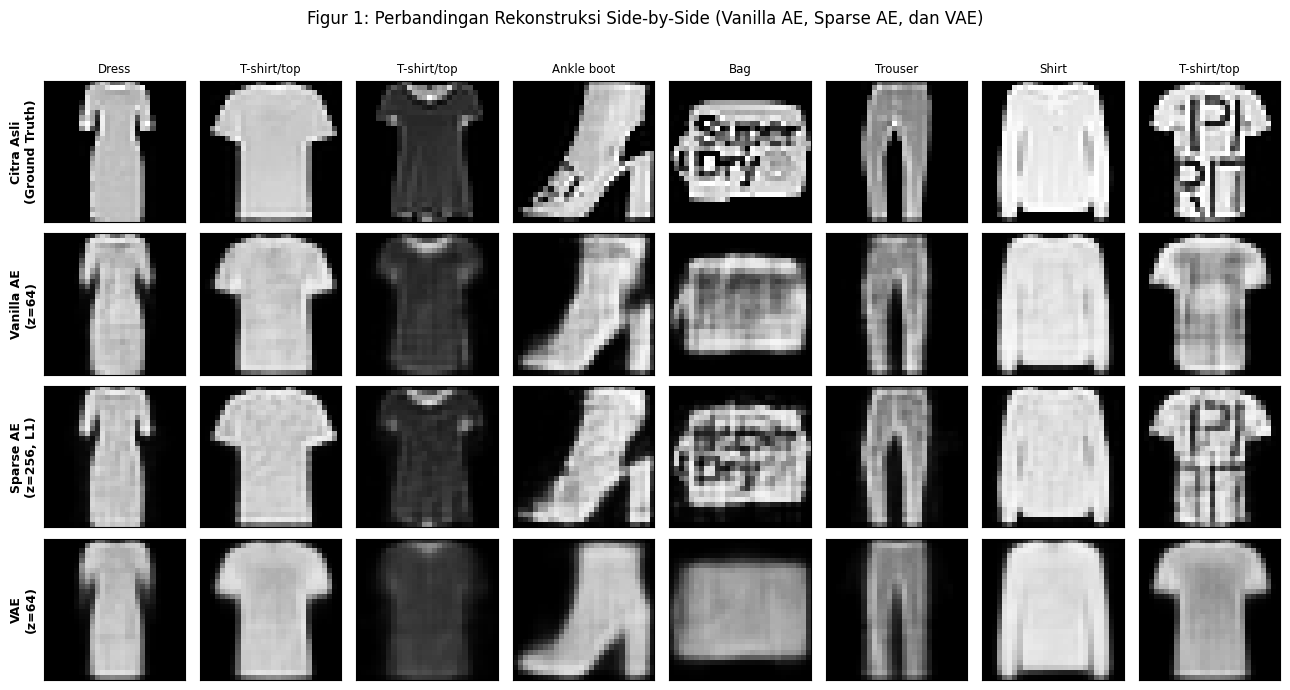

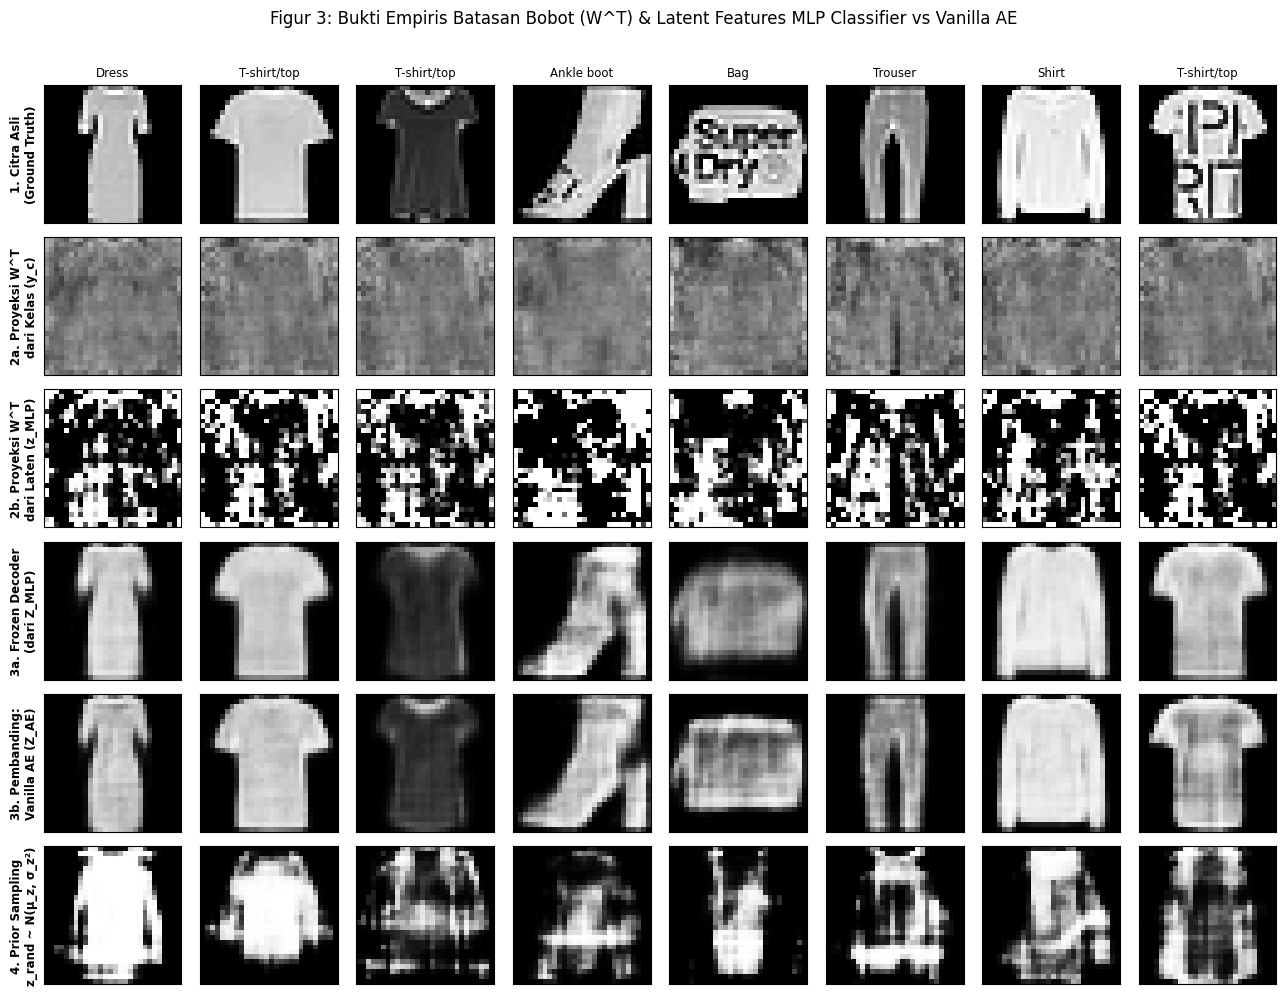

In [ ]:
vanilla_ae.eval()
sparse_ae.eval()
vae.eval()

RECON_METRICS = {}

for name, model in [("Vanilla AE", vanilla_ae), ("Sparse AE", sparse_ae), ("VAE", vae)]:
    if name == "VAE":
        fn = lambda x, m=model: m.decode(m.encode(x)[0])
    else:
        fn = lambda x, m=model: m(x)[0]

    mse_val, psnr_val, ssim_val = evaluate_reconstruction_metrics(fn, test_loader, device)
    RECON_METRICS[name] = {
        "Test MSE": mse_val,
        "Test PSNR (dB)": psnr_val,
        "Test SSIM": ssim_val
    }
    print(f"{name:12s} -> Test MSE: {mse_val:.6f} | Test PSNR: {psnr_val:.2f} dB | Test SSIM: {ssim_val:.4f}")

# Figur 1
sample_imgs, sample_lbls = next(iter(test_loader))
sample_imgs = sample_imgs[:8].to(device)
sample_lbls = sample_lbls[:8]

with torch.no_grad():
    recon_ae = vanilla_ae(sample_imgs)[0].cpu()
    recon_sae = sparse_ae(sample_imgs)[0].cpu()
    recon_vae = vae.decode(vae.encode(sample_imgs)[0]).cpu()

fig, axes = plt.subplots(4, 8, figsize=(13, 6.8))
rows_fig1 = [
    ("Citra Asli\n(Ground Truth)", sample_imgs.cpu()),
    ("Vanilla AE\n(z=64)", recon_ae),
    ("Sparse AE\n(z=256, L1)", recon_sae),
    ("VAE\n(z=64)", recon_vae)
]

for r_idx, (label_row, imgs_row) in enumerate(rows_fig1):
    for c_idx in range(8):
        axes[r_idx, c_idx].imshow(imgs_row[c_idx].squeeze(), cmap="gray", vmin=0, vmax=1)
        axes[r_idx, c_idx].set_xticks([])
        axes[r_idx, c_idx].set_yticks([])
        if r_idx == 0:
            axes[r_idx, c_idx].set_title(CLASS_NAMES[sample_lbls[c_idx].item()], fontsize=8.5)
        if c_idx == 0:
            axes[r_idx, c_idx].set_ylabel(label_row, fontsize=9, fontweight="bold")

plt.suptitle("Figur 1: Perbandingan Rekonstruksi Side-by-Side (Vanilla AE, Sparse AE, dan VAE)", fontsize=12, y=1.01)
plt.tight_layout()
plt.savefig("figures/figur1_rekonstruksi_ae.png", dpi=300, bbox_inches="tight")
plt.show()

# Figur 2
mlp_art = torch.load("checkpoints/bagian2_mlp_artifacts.pt")
with torch.no_grad():
    ae_for_fig3 = vanilla_ae(mlp_art["ground_truth"].to(device))[0].cpu()

fig, axes = plt.subplots(6, 8, figsize=(13, 9.8))
rows_fig3 = [
    ("1. Citra Asli\n(Ground Truth)", mlp_art["ground_truth"]),
    ("2a. Proyeksi W^T\ndari Kelas (y_c)", mlp_art["w_transpose_class"]),
    ("2b. Proyeksi W^T\ndari Laten (z_MLP)", mlp_art["w_transpose_latent"]),
    ("3a. Frozen Decoder\n(dari Z_MLP)", mlp_art["frozen_mlp_recon"]),
    ("3b. Pembanding:\nVanilla AE (Z_AE)", ae_for_fig3),
    ("4. Prior Sampling\nz_rand ~ N(μ_z, σ_z²)", mlp_art["mlp_prior_samples"])
]

for r_idx, (label_row, imgs_row) in enumerate(rows_fig3):
    for c_idx in range(8):
        axes[r_idx, c_idx].imshow(imgs_row[c_idx].squeeze(), cmap="gray", vmin=0, vmax=1)
        axes[r_idx, c_idx].set_xticks([])
        axes[r_idx, c_idx].set_yticks([])
        if r_idx == 0:
            axes[r_idx, c_idx].set_title(CLASS_NAMES[mlp_art["labels"][c_idx].item()], fontsize=8.5)
        if c_idx == 0:
            axes[r_idx, c_idx].set_ylabel(label_row, fontsize=8.5, fontweight="bold")

plt.suptitle("Figur 3: Bukti Empiris Batasan Bobot (W^T) & Latent Features MLP Classifier vs Vanilla AE", fontsize=12, y=1.01)
plt.tight_layout()
plt.savefig("figures/figur3_mlp_vs_ae_final.png", dpi=300, bbox_inches="tight")
plt.show()

## **4. Arsitektur & Pelatihan Keluarga GAN dan Diffusion**

In [ ]:
class GeneratorMLP(nn.Module):
    def __init__(self, noise_dim: int = 64, output_dim: int = 784):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(noise_dim, 256),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Linear(256, 512),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Linear(512, output_dim),
            nn.Tanh()
        )

    def forward(self, z: torch.Tensor) -> torch.Tensor:
        return self.net(z).view(-1, 1, 28, 28)


class DiscriminatorMLP(nn.Module):
    def __init__(self, input_dim: int = 784):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, 512),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Dropout(0.3),
            nn.Linear(512, 256),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Dropout(0.3),
            nn.Linear(256, 1)
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.net(x.view(x.size(0), -1))


set_seed(SEED)
gen_mlp = GeneratorMLP(noise_dim=CONFIG["latent_dim"], output_dim=CONFIG["input_dim"]).to(device)
disc_mlp = DiscriminatorMLP(input_dim=CONFIG["input_dim"]).to(device)

criterion_gan = nn.BCEWithLogitsLoss()
opt_g_mlp = optim.Adam(gen_mlp.parameters(), lr=2e-4, betas=(0.5, 0.999))
opt_d_mlp = optim.Adam(disc_mlp.parameters(), lr=2e-4, betas=(0.5, 0.999))

EPOCHS_GAN = 30
HISTORY["Vanilla GAN_G"] = []
HISTORY["Vanilla GAN_D"] = []
epoch_times = []

print("=== MELATIH VANILLA GAN (MLP) ===")
for epoch in range(1, EPOCHS_GAN + 1):
    t0 = time.time()
    gen_mlp.train()
    disc_mlp.train()
    g_loss_sum, d_loss_sum = 0.0, 0.0

    for imgs, _ in train_loader:
        real_imgs = scale_to_minus_one_one(imgs.to(device))
        bsz = real_imgs.size(0)
        real_labels = torch.ones(bsz, 1, device=device)
        fake_labels = torch.zeros(bsz, 1, device=device)

        # 1. Update Discriminator: max log(D(x)) + log(1 - D(G(z)))
        opt_d_mlp.zero_grad()
        out_real = disc_mlp(real_imgs)
        loss_d_real = criterion_gan(out_real, real_labels)

        z = torch.randn(bsz, CONFIG["latent_dim"], device=device)
        fake_imgs = gen_mlp(z)
        out_fake = disc_mlp(fake_imgs.detach())
        loss_d_fake = criterion_gan(out_fake, fake_labels)

        loss_d = loss_d_real + loss_d_fake
        loss_d.backward()
        opt_d_mlp.step()

        # 2. Update Generator: max log(D(G(z)))
        opt_g_mlp.zero_grad()
        out_fake_for_g = disc_mlp(fake_imgs)
        loss_g = criterion_gan(out_fake_for_g, real_labels)
        loss_g.backward()
        opt_g_mlp.step()

        d_loss_sum += loss_d.item() * bsz
        g_loss_sum += loss_g.item() * bsz

    epoch_times.append(time.time() - t0)
    avg_d = d_loss_sum / len(train_dataset)
    avg_g = g_loss_sum / len(train_dataset)
    HISTORY["Vanilla GAN_D"].append(avg_d)
    HISTORY["Vanilla GAN_G"].append(avg_g)

    if epoch % 5 == 0 or epoch == 1:
        print(f"Epoch [{epoch:02d}/{EPOCHS_GAN}] | D Loss: {avg_d:.4f} | G Loss: {avg_g:.4f} | Time: {epoch_times[-1]:.2f}s")

TRAIN_TIME_PER_EPOCH["Vanilla GAN"] = float(np.mean(epoch_times))
torch.save(gen_mlp.state_dict(), "checkpoints/vanilla_gan_gen.pth")

=== MELATIH VANILLA GAN (MLP) ===
Epoch [01/30] | D Loss: 0.7129 | G Loss: 1.6565 | Time: 8.63s
Epoch [05/30] | D Loss: 0.8356 | G Loss: 1.8862 | Time: 7.70s
Epoch [10/30] | D Loss: 0.9787 | G Loss: 1.5258 | Time: 8.17s
Epoch [15/30] | D Loss: 1.0711 | G Loss: 1.2981 | Time: 8.78s
Epoch [20/30] | D Loss: 1.1168 | G Loss: 1.1961 | Time: 8.76s
Epoch [25/30] | D Loss: 1.1415 | G Loss: 1.1647 | Time: 8.23s
Epoch [30/30] | D Loss: 1.1572 | G Loss: 1.1296 | Time: 7.73s


In [ ]:
def weights_init_dcgan(m):
    classname = m.__class__.__name__
    if classname.find("Conv") != -1:
        nn.init.normal_(m.weight.data, 0.0, 0.02)
    elif classname.find("BatchNorm") != -1:
        nn.init.normal_(m.weight.data, 1.0, 0.02)
        nn.init.constant_(m.bias.data, 0)


class GeneratorCNN(nn.Module):
    def __init__(self, noise_dim: int = 100):
        super().__init__()
        self.net = nn.Sequential(
            # Input: (B, 100, 1, 1) -> Output: (B, 256, 7, 7)
            nn.ConvTranspose2d(noise_dim, 256, kernel_size=7, stride=1, padding=0, bias=False),
            nn.BatchNorm2d(256),
            nn.ReLU(True),
            # Output: (B, 128, 14, 14)
            nn.ConvTranspose2d(256, 128, kernel_size=4, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(128),
            nn.ReLU(True),
            # Output: (B, 1, 28, 28)
            nn.ConvTranspose2d(128, 1, kernel_size=4, stride=2, padding=1, bias=False),
            nn.Tanh()
        )

    def forward(self, z: torch.Tensor) -> torch.Tensor:
        if z.dim() == 2:
            z = z.unsqueeze(-1).unsqueeze(-1)
        return self.net(z)


class DiscriminatorCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            # Input: (B, 1, 28, 28) -> Output: (B, 64, 14, 14)
            nn.Conv2d(1, 64, kernel_size=4, stride=2, padding=1, bias=False),
            nn.LeakyReLU(0.2, inplace=True),
            # Output: (B, 128, 7, 7)
            nn.Conv2d(64, 128, kernel_size=4, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(128),
            nn.LeakyReLU(0.2, inplace=True),
            # Output: (B, 1, 1, 1)
            nn.Conv2d(128, 1, kernel_size=7, stride=1, padding=0, bias=False)
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.net(x).view(-1, 1)


set_seed(SEED)
gen_dcgan = GeneratorCNN(noise_dim=CONFIG["noise_dim"]).to(device)
disc_dcgan = DiscriminatorCNN().to(device)
gen_dcgan.apply(weights_init_dcgan)
disc_dcgan.apply(weights_init_dcgan)

opt_g_dc = optim.Adam(gen_dcgan.parameters(), lr=2e-4, betas=(0.5, 0.999))
opt_d_dc = optim.Adam(disc_dcgan.parameters(), lr=2e-4, betas=(0.5, 0.999))

EPOCHS_DCGAN = 30
HISTORY["DCGAN_G"] = []
HISTORY["DCGAN_D"] = []
epoch_times = []

print("=== MELATIH DCGAN ===")
for epoch in range(1, EPOCHS_DCGAN + 1):
    t0 = time.time()
    gen_dcgan.train()
    disc_dcgan.train()
    g_loss_sum, d_loss_sum = 0.0, 0.0

    for imgs, _ in train_loader:
        real_imgs = scale_to_minus_one_one(imgs.to(device))
        bsz = real_imgs.size(0)
        real_labels = torch.ones(bsz, 1, device=device)
        fake_labels = torch.zeros(bsz, 1, device=device)

        # 1. Update Discriminator
        opt_d_dc.zero_grad()
        out_real = disc_dcgan(real_imgs)
        loss_d_real = criterion_gan(out_real, real_labels)

        z = torch.randn(bsz, CONFIG["noise_dim"], device=device)
        fake_imgs = gen_dcgan(z)
        out_fake = disc_dcgan(fake_imgs.detach())
        loss_d_fake = criterion_gan(out_fake, fake_labels)

        loss_d = loss_d_real + loss_d_fake
        loss_d.backward()
        opt_d_dc.step()

        # 2. Update Generator
        opt_g_dc.zero_grad()
        out_fake_for_g = disc_dcgan(fake_imgs)
        loss_g = criterion_gan(out_fake_for_g, real_labels)
        loss_g.backward()
        opt_g_dc.step()

        d_loss_sum += loss_d.item() * bsz
        g_loss_sum += loss_g.item() * bsz

    epoch_times.append(time.time() - t0)
    avg_d = d_loss_sum / len(train_dataset)
    avg_g = g_loss_sum / len(train_dataset)
    HISTORY["DCGAN_D"].append(avg_d)
    HISTORY["DCGAN_G"].append(avg_g)

    if epoch % 5 == 0 or epoch == 1:
        print(f"Epoch [{epoch:02d}/{EPOCHS_DCGAN}] | D Loss: {avg_d:.4f} | G Loss: {avg_g:.4f} | Time: {epoch_times[-1]:.2f}s")

TRAIN_TIME_PER_EPOCH["DCGAN"] = float(np.mean(epoch_times))
torch.save(gen_dcgan.state_dict(), "checkpoints/dcgan_gen.pth")

=== MELATIH DCGAN ===
Epoch [01/30] | D Loss: 0.6582 | G Loss: 1.7434 | Time: 16.46s
Epoch [05/30] | D Loss: 0.9715 | G Loss: 1.2944 | Time: 15.82s
Epoch [10/30] | D Loss: 1.1073 | G Loss: 1.1667 | Time: 15.99s
Epoch [15/30] | D Loss: 1.1607 | G Loss: 1.1303 | Time: 16.01s
Epoch [20/30] | D Loss: 1.1780 | G Loss: 1.1019 | Time: 15.91s
Epoch [25/30] | D Loss: 1.1883 | G Loss: 1.0844 | Time: 15.85s
Epoch [30/30] | D Loss: 1.1944 | G Loss: 1.0710 | Time: 15.89s


In [ ]:
import math

class SinusoidalTimeEmbedding(nn.Module):
    def __init__(self, dim: int):
        super().__init__()
        self.dim = dim

    def forward(self, t: torch.Tensor) -> torch.Tensor:
        half_dim = self.dim // 2
        emb = math.log(10000) / (half_dim - 1)
        emb = torch.exp(torch.arange(half_dim, device=t.device, dtype=torch.float32) * -emb)
        emb = t.float().unsqueeze(1) * emb.unsqueeze(0)
        return torch.cat([torch.sin(emb), torch.cos(emb)], dim=-1)


class ResBlockDDPM(nn.Module):
    def __init__(self, in_ch: int, out_ch: int, time_dim: int):
        super().__init__()
        self.conv1 = nn.Conv2d(in_ch, out_ch, kernel_size=3, padding=1)
        self.norm1 = nn.GroupNorm(8, out_ch)
        self.conv2 = nn.Conv2d(out_ch, out_ch, kernel_size=3, padding=1)
        self.norm2 = nn.GroupNorm(8, out_ch)
        self.time_mlp = nn.Linear(time_dim, out_ch)
        self.shortcut = nn.Conv2d(in_ch, out_ch, kernel_size=1) if in_ch != out_ch else nn.Identity()

    def forward(self, x: torch.Tensor, t_emb: torch.Tensor) -> torch.Tensor:
        h = F.silu(self.norm1(self.conv1(x)))
        h = h + self.time_mlp(F.silu(t_emb))[:, :, None, None]
        h = F.silu(self.norm2(self.conv2(h)))
        return h + self.shortcut(x)


class UNetDDPM(nn.Module):
    def __init__(self, time_dim: int = 128):
        super().__init__()
        self.time_mlp = nn.Sequential(
            SinusoidalTimeEmbedding(time_dim),
            nn.Linear(time_dim, time_dim),
            nn.SiLU()
        )
        # Encoder (28x28 -> 14x14 -> 7x7)
        self.enc1 = ResBlockDDPM(1, 64, time_dim)
        self.down1 = nn.Conv2d(64, 64, kernel_size=4, stride=2, padding=1)
        self.enc2 = ResBlockDDPM(64, 128, time_dim)
        self.down2 = nn.Conv2d(128, 128, kernel_size=4, stride=2, padding=1)

        # Bottleneck (7x7)
        self.bot = ResBlockDDPM(128, 256, time_dim)

        # Decoder (7x7 -> 14x14 -> 28x28)
        self.up1 = nn.ConvTranspose2d(256, 128, kernel_size=4, stride=2, padding=1)
        self.dec1 = ResBlockDDPM(256, 128, time_dim)
        self.up2 = nn.ConvTranspose2d(128, 64, kernel_size=4, stride=2, padding=1)
        self.dec2 = ResBlockDDPM(128, 64, time_dim)

        self.out_conv = nn.Conv2d(64, 1, kernel_size=1)

    def forward(self, x: torch.Tensor, t: torch.Tensor) -> torch.Tensor:
        t_emb = self.time_mlp(t)

        e1 = self.enc1(x, t_emb)                 # (B, 64, 28, 28)
        e2 = self.enc2(self.down1(e1), t_emb)    # (B, 128, 14, 14)
        b = self.bot(self.down2(e2), t_emb)      # (B, 256, 7, 7)

        d1 = self.up1(b)                         # (B, 128, 14, 14)
        d1 = self.dec1(torch.cat([d1, e2], dim=1), t_emb)

        d2 = self.up2(d1)                        # (B, 64, 28, 28)
        d2 = self.dec2(torch.cat([d2, e1], dim=1), t_emb)

        return self.out_conv(d2)


class GaussianDiffusion(nn.Module):
    def __init__(self, model: nn.Module, timesteps: int = 300, beta_start: float = 1e-4, beta_end: float = 0.02):
        super().__init__()
        self.model = model
        self.timesteps = timesteps

        betas = torch.linspace(beta_start, beta_end, timesteps)
        alphas = 1.0 - betas
        alphas_cumprod = torch.cumprod(alphas, dim=0)
        alphas_cumprod_prev = F.pad(alphas_cumprod[:-1], (1, 0), value=1.0)

        self.register_buffer("betas", betas)
        self.register_buffer("alphas", alphas)
        self.register_buffer("alphas_cumprod", alphas_cumprod)
        self.register_buffer("sqrt_alphas_cumprod", torch.sqrt(alphas_cumprod))
        self.register_buffer("sqrt_one_minus_alphas_cumprod", torch.sqrt(1.0 - alphas_cumprod))
        self.register_buffer("sqrt_recip_alphas", torch.sqrt(1.0 / alphas))
        self.register_buffer("posterior_variance", betas * (1.0 - alphas_cumprod_prev) / (1.0 - alphas_cumprod))

    def q_sample(self, x_start: torch.Tensor, t: torch.Tensor, noise: torch.Tensor) -> torch.Tensor:
        s1 = self.sqrt_alphas_cumprod[t][:, None, None, None]
        s2 = self.sqrt_one_minus_alphas_cumprod[t][:, None, None, None]
        return s1 * x_start + s2 * noise

    def p_losses(self, x_start: torch.Tensor, t: torch.Tensor) -> torch.Tensor:
        noise = torch.randn_like(x_start)
        x_noisy = self.q_sample(x_start, t, noise)
        predicted_noise = self.model(x_noisy, t)
        return F.mse_loss(predicted_noise, noise)

    @torch.no_grad()
    def sample(self, batch_size: int, device: torch.device, return_trajectory: bool = False):
        x = torch.randn(batch_size, 1, 28, 28, device=device)
        trajectory = []
        capture_steps = set(np.linspace(self.timesteps - 1, 0, 8, dtype=int))

        for i in reversed(range(self.timesteps)):
            t = torch.full((batch_size,), i, device=device, dtype=torch.long)
            pred_noise = self.model(x, t)

            beta_t = self.betas[i]
            sqrt_one_minus_ac_t = self.sqrt_one_minus_alphas_cumprod[i]
            sqrt_recip_alpha_t = self.sqrt_recip_alphas[i]

            mean = sqrt_recip_alpha_t * (x - (beta_t / sqrt_one_minus_ac_t) * pred_noise)

            if i > 0:
                noise = torch.randn_like(x)
                sigma_t = torch.sqrt(self.posterior_variance[i])
                x = mean + sigma_t * noise
            else:
                x = mean

            if return_trajectory and i in capture_steps:
                trajectory.append((i, scale_to_zero_one(x.clone()).cpu()))

        x_out = scale_to_zero_one(x)
        if return_trajectory:
            return x_out, trajectory
        return x_out


set_seed(SEED)
unet_ddpm = UNetDDPM(time_dim=128).to(device)
ddpm = GaussianDiffusion(unet_ddpm, timesteps=300).to(device)
opt_ddpm = optim.Adam(ddpm.parameters(), lr=2e-4)

EPOCHS_DDPM = 20
HISTORY["DDPM"] = []
epoch_times = []

print("=== MELATIH DDPM ===")
for epoch in range(1, EPOCHS_DDPM + 1):
    t0 = time.time()
    ddpm.train()
    running_loss = 0.0

    for imgs, _ in train_loader:
        real_imgs = scale_to_minus_one_one(imgs.to(device))
        bsz = real_imgs.size(0)
        t = torch.randint(0, ddpm.timesteps, (bsz,), device=device).long()

        opt_ddpm.zero_grad()
        loss = ddpm.p_losses(real_imgs, t)
        loss.backward()
        opt_ddpm.step()

        running_loss += loss.item() * bsz

    epoch_times.append(time.time() - t0)
    avg_loss = running_loss / len(train_dataset)
    HISTORY["DDPM"].append(avg_loss)

    if epoch % 5 == 0 or epoch == 1:
        print(f"Epoch [{epoch:02d}/{EPOCHS_DDPM}] | Noise MSE Loss: {avg_loss:.6f} | Time: {epoch_times[-1]:.2f}s")

TRAIN_TIME_PER_EPOCH["DDPM"] = float(np.mean(epoch_times))
torch.save(ddpm.state_dict(), "checkpoints/ddpm.pth")

torch.save({
    "history": HISTORY,
    "train_time_per_epoch": TRAIN_TIME_PER_EPOCH,
    "recon_metrics": RECON_METRICS
}, "checkpoints/training_logs_all.pt")

=== MELATIH DDPM ===
Epoch [01/20] | Noise MSE Loss: 0.134031 | Time: 47.45s
Epoch [05/20] | Noise MSE Loss: 0.076538 | Time: 47.42s
Epoch [10/20] | Noise MSE Loss: 0.071521 | Time: 47.38s
Epoch [15/20] | Noise MSE Loss: 0.068240 | Time: 47.36s
Epoch [20/20] | Noise MSE Loss: 0.066778 | Time: 47.33s


## **5. Evaluasi dan Visualisasi**

In [ ]:
from torchmetrics.image.fid import FrechetInceptionDistance

set_seed(SEED)
vae.eval()
gen_mlp.eval()
gen_dcgan.eval()
ddpm.eval()

def compute_fid_score(generator_fn, test_loader, num_gen_samples: int = 1024, batch_size: int = 64):
    fid = FrechetInceptionDistance(feature=2048, normalize=True).to(device)

    # 1. Ekstrak statistik fitur citra asli dari Test Set (konversi grayscale 1-ch -> RGB 3-ch)
    real_count = 0
    with torch.no_grad():
        for imgs, _ in test_loader:
            imgs_rgb = imgs.to(device).repeat(1, 3, 1, 1)
            fid.update(imgs_rgb, real=True)
            real_count += imgs.size(0)
            if real_count >= num_gen_samples:
                break

    # 2. Ekstrak statistik fitur citra sintetis hasil sampling prior acak
    gen_count = 0
    with torch.no_grad():
        while gen_count < num_gen_samples:
            curr_bsz = min(batch_size, num_gen_samples - gen_count)
            fake_imgs = generator_fn(curr_bsz)
            fake_rgb = torch.clamp(fake_imgs, 0.0, 1.0).repeat(1, 3, 1, 1)
            fid.update(fake_rgb, real=False)
            gen_count += curr_bsz

    return fid.compute().item()

print("=== MENGHITUNG SKOR FID (1.024 SAMPEL SINTETIS PER MODEL) ===")
FID_SCORES = {}

FID_SCORES["VAE"] = compute_fid_score(
    lambda b: vae.decode(torch.randn(b, CONFIG["latent_dim"], device=device)),
    test_loader
)
print(f"FID VAE         : {FID_SCORES['VAE']:.2f}")

FID_SCORES["Vanilla GAN"] = compute_fid_score(
    lambda b: scale_to_zero_one(gen_mlp(torch.randn(b, CONFIG["latent_dim"], device=device))),
    test_loader
)
print(f"FID Vanilla GAN : {FID_SCORES['Vanilla GAN']:.2f}")

FID_SCORES["DCGAN"] = compute_fid_score(
    lambda b: scale_to_zero_one(gen_dcgan(torch.randn(b, CONFIG["noise_dim"], device=device))),
    test_loader
)
print(f"FID DCGAN       : {FID_SCORES['DCGAN']:.2f}")

FID_SCORES["DDPM"] = compute_fid_score(
    lambda b: ddpm.sample(b, device=device, return_trajectory=False),
    test_loader
)
print(f"FID DDPM        : {FID_SCORES['DDPM']:.2f}")

=== MENGHITUNG SKOR FID (1.024 SAMPEL SINTETIS PER MODEL) ===


Downloading: "https://github.com/toshas/torch-fidelity/releases/download/v0.2.0/weights-inception-2015-12-05-6726825d.pth" to /root/.cache/torch/hub/checkpoints/weights-inception-2015-12-05-6726825d.pth
100%|██████████| 91.2M/91.2M [00:00<00:00, 199MB/s]


FID VAE         : 101.95
FID Vanilla GAN : 151.55
FID DCGAN       : 40.74
FID DDPM        : 61.94


### Latency Evaluation

In [ ]:
import time
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

def measure_latency_ms(fn, n_warmup=10, n_runs=50):
    with torch.no_grad():
        for _ in range(n_warmup):
            _ = fn()
        if device.type == "cuda":
            torch.cuda.synchronize()

        start = time.perf_counter()
        for _ in range(n_runs):
            _ = fn()
        if device.type == "cuda":
            torch.cuda.synchronize()
        end = time.perf_counter()

    return ((end - start) / n_runs) * 1000  # Satuan ms / batch 64

x_64 = torch.randn(64, 1, 28, 28, device=device)
z_64 = torch.randn(64, 64, device=device)
z_noise_64 = torch.randn(64, 100, device=device)

latencies = {
    "Vanilla AE": measure_latency_ms(lambda: vanilla_ae(x_64)),
    "Sparse AE": measure_latency_ms(lambda: sparse_ae(x_64)),
    "VAE (Sampling)": measure_latency_ms(lambda: vae.decode(z_64)),
    "Vanilla GAN": measure_latency_ms(lambda: gen_mlp(z_64)),
    "DCGAN": measure_latency_ms(lambda: gen_dcgan(z_noise_64)),
    # DDPM lambat karena iteratif, cukup 2 warmup & 5 run agar tidak menunggu lama
    "DDPM": measure_latency_ms(lambda: ddpm.sample(64, device=device, return_trajectory=False), n_warmup=2, n_runs=5),
}

print("=== HASIL LATENCY (ms / batch 64) ===")
for name, ms in latencies.items():
    print(f"{name:<15} : {ms:.2f} ms")

=== HASIL LATENCY (ms / batch 64) ===
Vanilla AE      : 0.20 ms
Sparse AE       : 0.10 ms
VAE (Sampling)  : 0.09 ms
Vanilla GAN     : 0.13 ms
DCGAN           : 8.57 ms
DDPM            : 5158.64 ms


### Figur 1

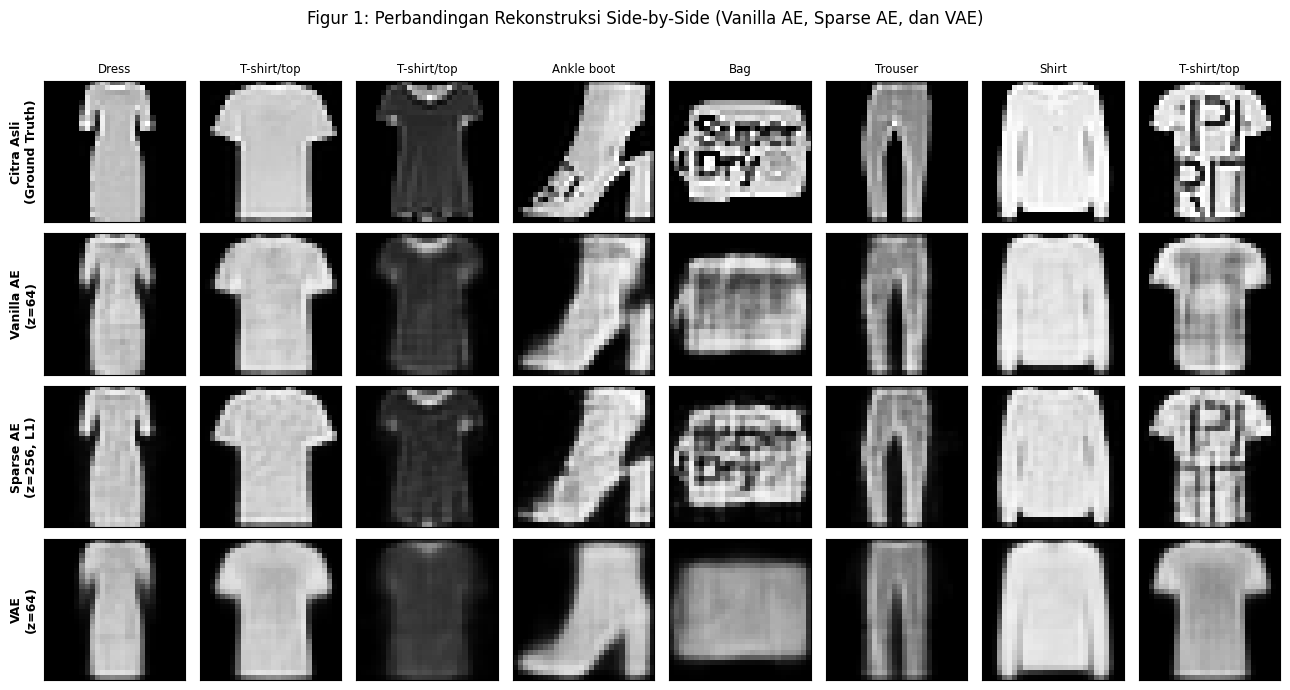

In [ ]:
vanilla_ae.eval()
sparse_ae.eval()
vae.eval()

# Ambil 8 sampel citra pertama dari Test Set
sample_imgs, sample_lbls = next(iter(test_loader))
sample_imgs = sample_imgs[:8].to(device)
sample_lbls = sample_lbls[:8]

with torch.no_grad():
    recon_ae = vanilla_ae(sample_imgs)[0].cpu()
    recon_sae = sparse_ae(sample_imgs)[0].cpu()
    recon_vae = vae.decode(vae.encode(sample_imgs)[0]).cpu()

fig, axes = plt.subplots(4, 8, figsize=(13, 6.8))
rows_fig1 = [
    ("Citra Asli\n(Ground Truth)", sample_imgs.cpu()),
    ("Vanilla AE\n(z=64)", recon_ae),
    ("Sparse AE\n(z=256, L1)", recon_sae),
    ("VAE\n(z=64)", recon_vae)
]

for r_idx, (label_row, imgs_row) in enumerate(rows_fig1):
    for c_idx in range(8):
        axes[r_idx, c_idx].imshow(imgs_row[c_idx].squeeze(), cmap="gray", vmin=0, vmax=1)
        axes[r_idx, c_idx].set_xticks([])
        axes[r_idx, c_idx].set_yticks([])
        if r_idx == 0:
            axes[r_idx, c_idx].set_title(CLASS_NAMES[sample_lbls[c_idx].item()], fontsize=8.5)
        if c_idx == 0:
            axes[r_idx, c_idx].set_ylabel(label_row, fontsize=9, fontweight="bold")

plt.suptitle("Figur 1: Perbandingan Rekonstruksi Side-by-Side (Vanilla AE, Sparse AE, dan VAE)", fontsize=12, y=1.01)
plt.tight_layout()
plt.savefig("figures/figur1_rekonstruksi_ae.png", dpi=300, bbox_inches="tight")
plt.show()

### Figur 2

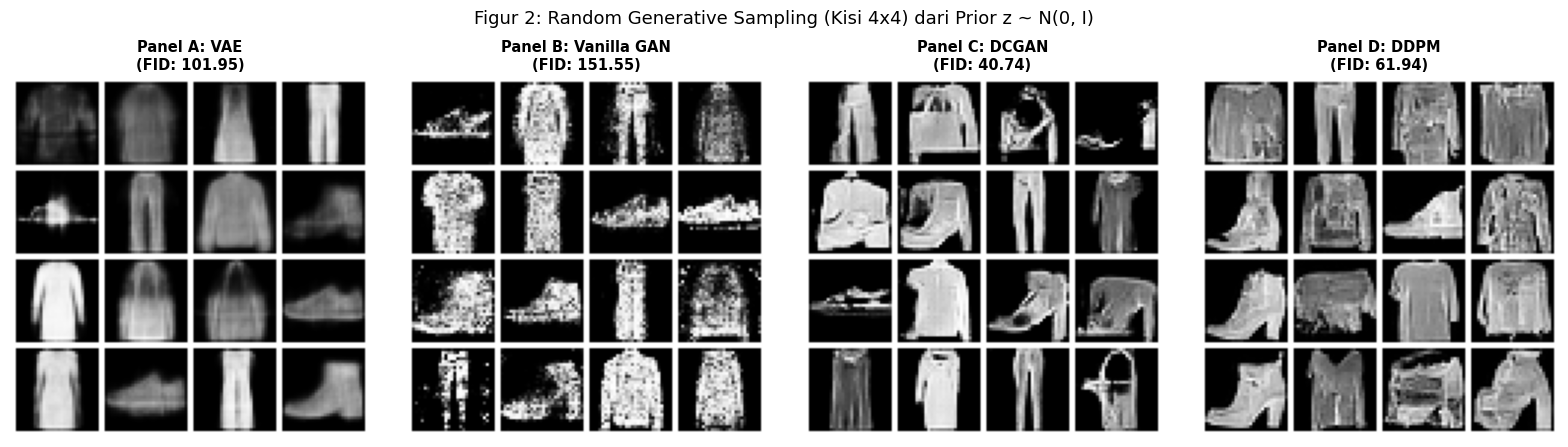

In [ ]:

set_seed(SEED)
with torch.no_grad():
    samples_vae = vae.decode(torch.randn(16, CONFIG["latent_dim"], device=device)).cpu()
    samples_gan = scale_to_zero_one(gen_mlp(torch.randn(16, CONFIG["latent_dim"], device=device))).cpu()
    samples_dcgan = scale_to_zero_one(gen_dcgan(torch.randn(16, CONFIG["noise_dim"], device=device))).cpu()
    samples_ddpm, ddpm_trajectory = ddpm.sample(16, device=device, return_trajectory=True)
    samples_ddpm = samples_ddpm.cpu()

fig, axes = plt.subplots(1, 4, figsize=(16, 4.3))
panels_fig2 = [
    (f"Panel A: VAE\n(FID: {FID_SCORES['VAE']:.2f})", samples_vae),
    (f"Panel B: Vanilla GAN\n(FID: {FID_SCORES['Vanilla GAN']:.2f})", samples_gan),
    (f"Panel C: DCGAN\n(FID: {FID_SCORES['DCGAN']:.2f})", samples_dcgan),
    (f"Panel D: DDPM\n(FID: {FID_SCORES['DDPM']:.2f})", samples_ddpm)
]

for ax, (title, batch_imgs) in zip(axes, panels_fig2):
    grid = make_grid(batch_imgs, nrow=4, padding=2, pad_value=1.0)
    ax.imshow(grid.permute(1, 2, 0).squeeze(), cmap="gray", vmin=0, vmax=1)
    ax.set_title(title, fontsize=10.5, fontweight="bold")
    ax.axis("off")

plt.suptitle("Figur 2: Random Generative Sampling (Kisi 4x4) dari Prior z ~ N(0, I)", fontsize=13, y=1.03)
plt.tight_layout()
plt.savefig("figures/figur2_random_sampling.png", dpi=300, bbox_inches="tight")
plt.show()

### Figur 3

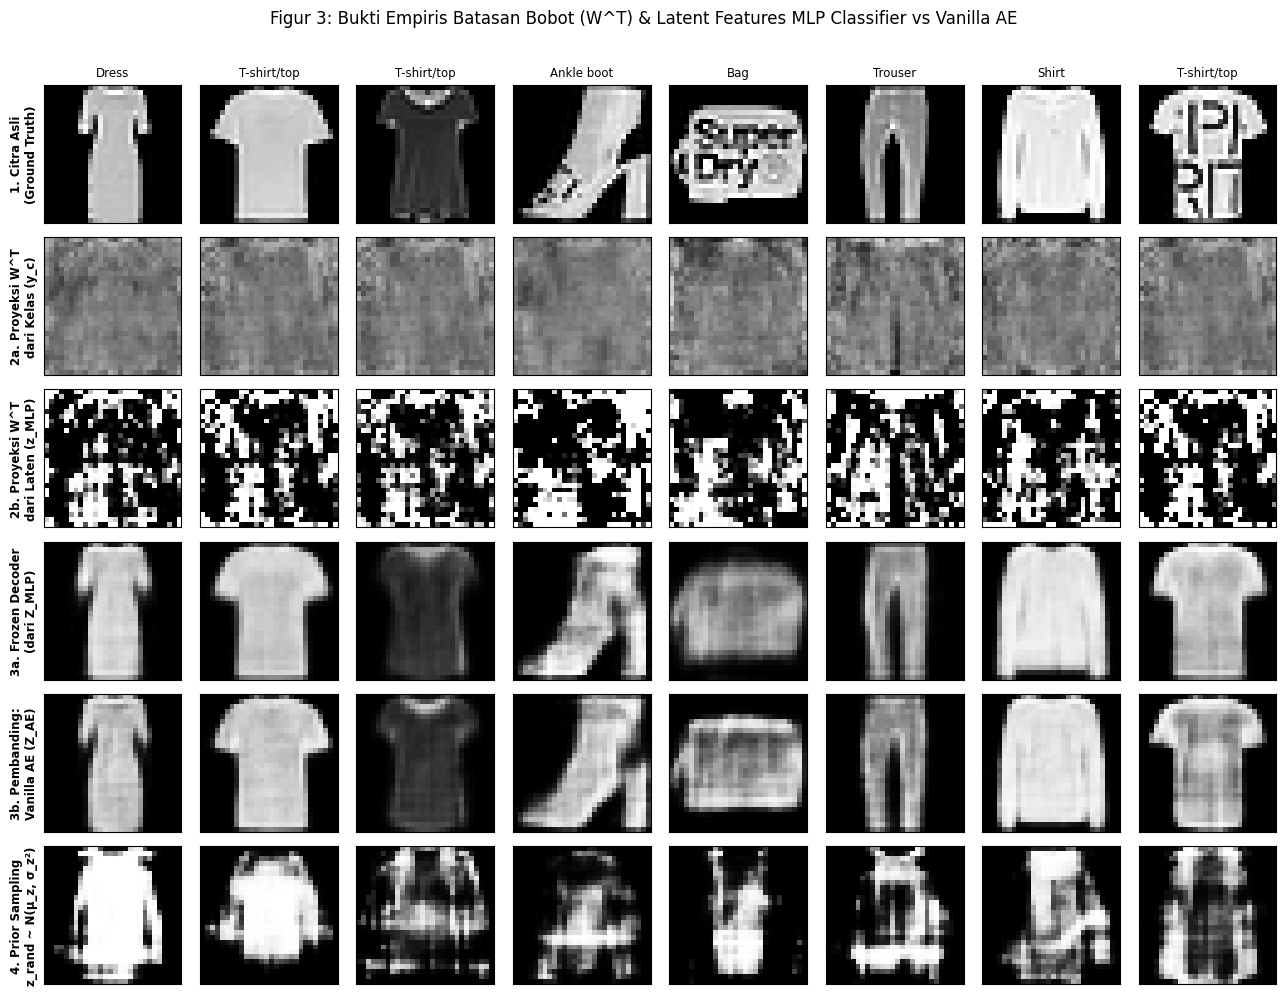

In [ ]:
# Dari bagian 2
mlp_art = torch.load("checkpoints/bagian2_mlp_artifacts.pt")

vanilla_ae.eval()
with torch.no_grad():
    ae_for_fig3 = vanilla_ae(mlp_art["ground_truth"].to(device))[0].cpu()

fig, axes = plt.subplots(6, 8, figsize=(13, 9.8))
rows_fig3 = [
    ("1. Citra Asli\n(Ground Truth)", mlp_art["ground_truth"]),
    ("2a. Proyeksi W^T\ndari Kelas (y_c)", mlp_art["w_transpose_class"]),
    ("2b. Proyeksi W^T\ndari Laten (z_MLP)", mlp_art["w_transpose_latent"]),
    ("3a. Frozen Decoder\n(dari Z_MLP)", mlp_art["frozen_mlp_recon"]),
    ("3b. Pembanding:\nVanilla AE (Z_AE)", ae_for_fig3),
    ("4. Prior Sampling\nz_rand ~ N(μ_z, σ_z²)", mlp_art["mlp_prior_samples"])
]

for r_idx, (label_row, imgs_row) in enumerate(rows_fig3):
    for c_idx in range(8):
        axes[r_idx, c_idx].imshow(imgs_row[c_idx].squeeze(), cmap="gray", vmin=0, vmax=1)
        axes[r_idx, c_idx].set_xticks([])
        axes[r_idx, c_idx].set_yticks([])
        if r_idx == 0:
            axes[r_idx, c_idx].set_title(CLASS_NAMES[mlp_art["labels"][c_idx].item()], fontsize=8.5)
        if c_idx == 0:
            axes[r_idx, c_idx].set_ylabel(label_row, fontsize=8.5, fontweight="bold")

plt.suptitle("Figur 3: Bukti Empiris Batasan Bobot (W^T) & Latent Features MLP Classifier vs Vanilla AE", fontsize=12, y=1.01)
plt.tight_layout()
plt.savefig("figures/figur3_mlp_vs_ae_final.png", dpi=300, bbox_inches="tight")
plt.show()

### Figur 4

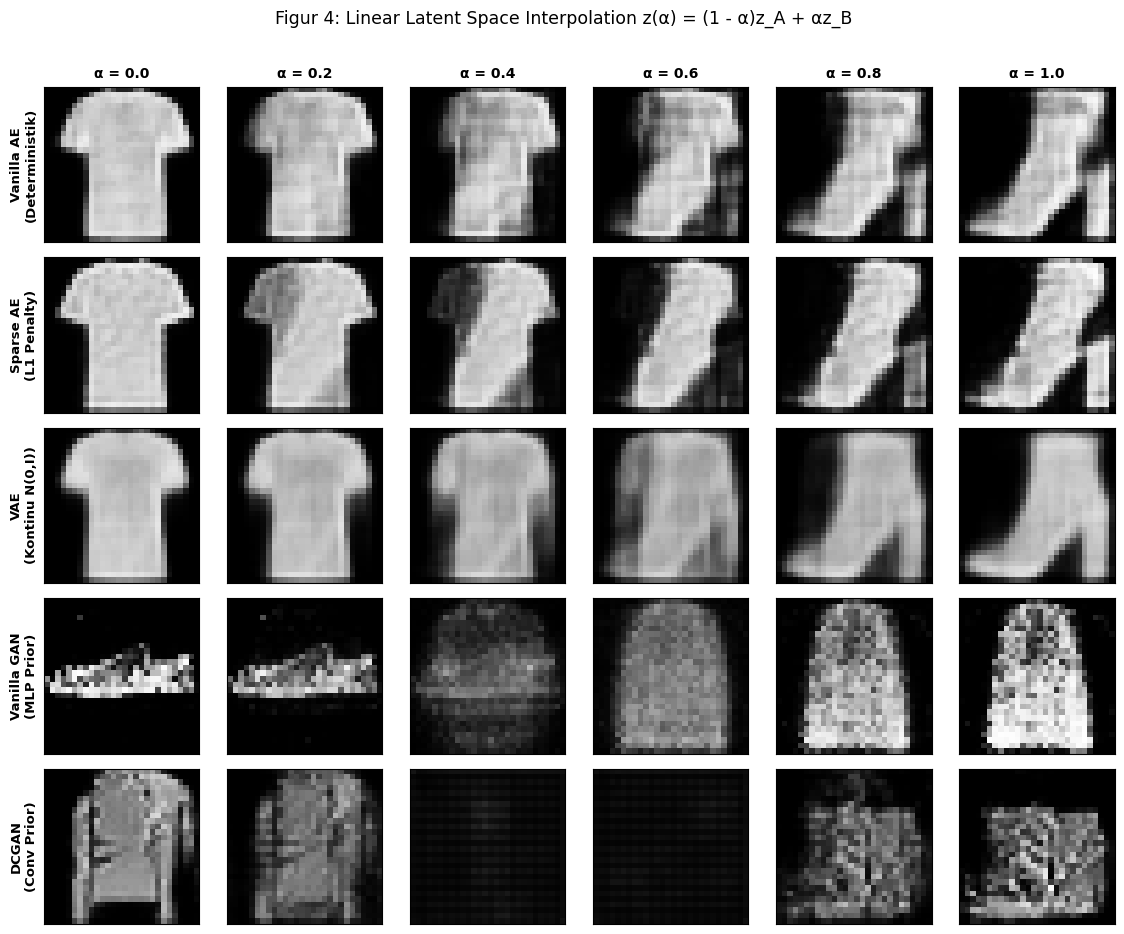

In [ ]:
set_seed(SEED)
alphas = [0.0, 0.2, 0.4, 0.6, 0.8, 1.0]

# Pilih 1 citra kelas 0 (T-shirt/top) dan 1 citra kelas 9 (Ankle boot) dari Test Set
idx_a = (Y_test_tensor == 0).nonzero(as_tuple=True)[0][0].item()
idx_b = (Y_test_tensor == 9).nonzero(as_tuple=True)[0][0].item()
img_a = X_test_tensor[idx_a:idx_a+1].to(device)
img_b = X_test_tensor[idx_b:idx_b+1].to(device)

def interpolate_vectors(z_a: torch.Tensor, z_b: torch.Tensor, alpha_list):
    return torch.cat([(1.0 - a) * z_a + a * z_b for a in alpha_list], dim=0)

with torch.no_grad():
    # 1. Vanilla AE
    z_a_ae, z_b_ae = vanilla_ae.encode(img_a), vanilla_ae.encode(img_b)
    interp_ae = vanilla_ae.decode(interpolate_vectors(z_a_ae, z_b_ae, alphas)).cpu()

    # 2. Sparse AE
    z_a_sae, z_b_sae = sparse_ae.encode(img_a), sparse_ae.encode(img_b)
    interp_sae = sparse_ae.decode(interpolate_vectors(z_a_sae, z_b_sae, alphas)).cpu()

    # 3. VAE (menggunakan vektor mean mu)
    z_a_vae, _ = vae.encode(img_a)
    z_b_vae, _ = vae.encode(img_b)
    interp_vae = vae.decode(interpolate_vectors(z_a_vae, z_b_vae, alphas)).cpu()

    # 4. Vanilla GAN (dua titik prior kontras z_A, z_B ~ N(0, I_64))
    z_a_gan = torch.randn(1, CONFIG["latent_dim"], device=device)
    z_b_gan = -z_a_gan
    interp_gan = scale_to_zero_one(gen_mlp(interpolate_vectors(z_a_gan, z_b_gan, alphas))).cpu()

    # 5. DCGAN (dua titik prior kontras z_A, z_B ~ N(0, I_100))
    z_a_dc = torch.randn(1, CONFIG["noise_dim"], device=device)
    z_b_dc = -z_a_dc
    interp_dc = scale_to_zero_one(gen_dcgan(interpolate_vectors(z_a_dc, z_b_dc, alphas))).cpu()

fig, axes = plt.subplots(5, len(alphas), figsize=(11.5, 9.2))
rows_fig4 = [
    ("Vanilla AE\n(Deterministik)", interp_ae),
    ("Sparse AE\n(L1 Penalty)", interp_sae),
    ("VAE\n(Kontinu N(0,I))", interp_vae),
    ("Vanilla GAN\n(MLP Prior)", interp_gan),
    ("DCGAN\n(Conv Prior)", interp_dc)
]

for r_idx, (model_label, imgs_seq) in enumerate(rows_fig4):
    for c_idx, a_val in enumerate(alphas):
        axes[r_idx, c_idx].imshow(imgs_seq[c_idx].squeeze(), cmap="gray", vmin=0, vmax=1)
        axes[r_idx, c_idx].set_xticks([])
        axes[r_idx, c_idx].set_yticks([])
        if r_idx == 0:
            axes[r_idx, c_idx].set_title(f"α = {a_val:.1f}", fontsize=10, fontweight="bold")
        if c_idx == 0:
            axes[r_idx, c_idx].set_ylabel(model_label, fontsize=9.5, fontweight="bold")

plt.suptitle("Figur 4: Linear Latent Space Interpolation z(α) = (1 - α)z_A + αz_B", fontsize=12.5, y=1.01)
plt.tight_layout()
plt.savefig("figures/figur4_latent_interpolation.png", dpi=300, bbox_inches="tight")
plt.show()

### Figur 5

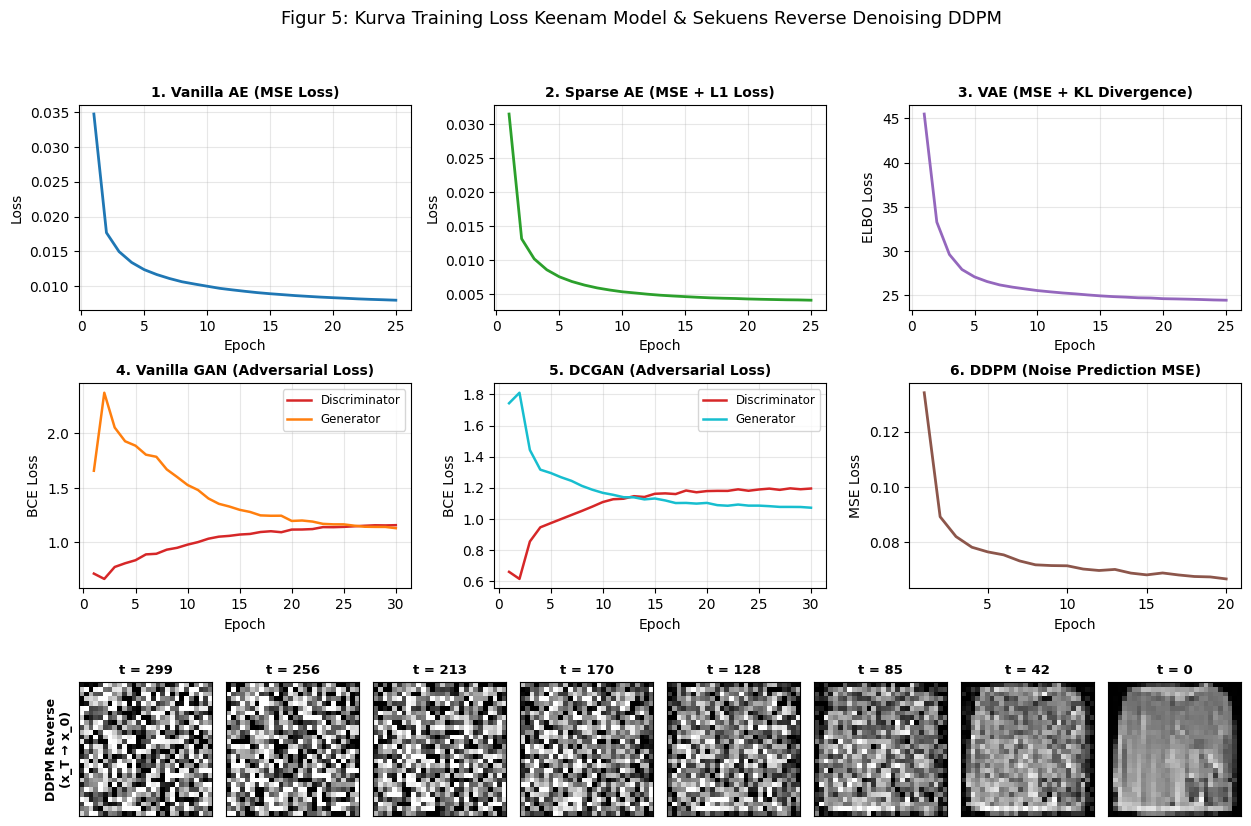

In [ ]:
fig = plt.figure(figsize=(15, 9.5))
gs = fig.add_gridspec(3, 3, height_ratios=[1, 1, 0.85], hspace=0.38, wspace=0.25)

# Panel 1: Vanilla AE
ax1 = fig.add_subplot(gs[0, 0])
ax1.plot(range(1, len(HISTORY["Vanilla AE"]) + 1), HISTORY["Vanilla AE"], color="#1f77b4", lw=2)
ax1.set_title("1. Vanilla AE (MSE Loss)", fontweight="bold", fontsize=10)
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Loss")
ax1.grid(True, alpha=0.3)

# Panel 2: Sparse AE
ax2 = fig.add_subplot(gs[0, 1])
ax2.plot(range(1, len(HISTORY["Sparse AE"]) + 1), HISTORY["Sparse AE"], color="#2ca02c", lw=2)
ax2.set_title("2. Sparse AE (MSE + L1 Loss)", fontweight="bold", fontsize=10)
ax2.set_xlabel("Epoch")
ax2.set_ylabel("Loss")
ax2.grid(True, alpha=0.3)

# Panel 3: VAE
ax3 = fig.add_subplot(gs[0, 2])
ax3.plot(range(1, len(HISTORY["VAE"]) + 1), HISTORY["VAE"], color="#9467bd", lw=2)
ax3.set_title("3. VAE (MSE + KL Divergence)", fontweight="bold", fontsize=10)
ax3.set_xlabel("Epoch")
ax3.set_ylabel("ELBO Loss")
ax3.grid(True, alpha=0.3)

# Panel 4: Vanilla GAN (G & D)
ax4 = fig.add_subplot(gs[1, 0])
epochs_gan_x = range(1, len(HISTORY["Vanilla GAN_G"]) + 1)
ax4.plot(epochs_gan_x, HISTORY["Vanilla GAN_D"], label="Discriminator", color="#d62728", lw=1.8)
ax4.plot(epochs_gan_x, HISTORY["Vanilla GAN_G"], label="Generator", color="#ff7f0e", lw=1.8)
ax4.set_title("4. Vanilla GAN (Adversarial Loss)", fontweight="bold", fontsize=10)
ax4.set_xlabel("Epoch")
ax4.set_ylabel("BCE Loss")
ax4.legend(fontsize=8.5)
ax4.grid(True, alpha=0.3)

# Panel 5: DCGAN (G & D)
ax5 = fig.add_subplot(gs[1, 1])
epochs_dc_x = range(1, len(HISTORY["DCGAN_G"]) + 1)
ax5.plot(epochs_dc_x, HISTORY["DCGAN_D"], label="Discriminator", color="#d62728", lw=1.8)
ax5.plot(epochs_dc_x, HISTORY["DCGAN_G"], label="Generator", color="#17becf", lw=1.8)
ax5.set_title("5. DCGAN (Adversarial Loss)", fontweight="bold", fontsize=10)
ax5.set_xlabel("Epoch")
ax5.set_ylabel("BCE Loss")
ax5.legend(fontsize=8.5)
ax5.grid(True, alpha=0.3)

# Panel 6: DDPM Noise Prediction Loss
ax6 = fig.add_subplot(gs[1, 2])
ax6.plot(range(1, len(HISTORY["DDPM"]) + 1), HISTORY["DDPM"], color="#8c564b", lw=2)
ax6.set_title("6. DDPM (Noise Prediction MSE)", fontweight="bold", fontsize=10)
ax6.set_xlabel("Epoch")
ax6.set_ylabel("MSE Loss")
ax6.grid(True, alpha=0.3)

# Panel Bawah (Span 3 Kolom): DDPM Reverse Diffusion Trajectory (x_T -> x_0)
gs_traj = gs[2, :].subgridspec(1, len(ddpm_trajectory), wspace=0.1)
for idx, (step_t, batch_step_imgs) in enumerate(ddpm_trajectory):
    ax_t = fig.add_subplot(gs_traj[0, idx])
    ax_t.imshow(batch_step_imgs[0].squeeze(), cmap="gray", vmin=0, vmax=1)
    ax_t.set_title(f"t = {step_t}", fontsize=9.5, fontweight="bold")
    ax_t.set_xticks([])
    ax_t.set_yticks([])
    if idx == 0:
        ax_t.set_ylabel("DDPM Reverse\n(x_T → x_0)", fontsize=9, fontweight="bold")

plt.suptitle("Figur 5: Kurva Training Loss Keenam Model & Sekuens Reverse Denoising DDPM", fontsize=13, y=0.98)
plt.savefig("figures/figur5_loss_dan_ddpm_trajectory.png", dpi=300, bbox_inches="tight")
plt.show()

## **6. Laporan**

In [ ]:
def measure_latency_ms(fn, num_warmup: int = 5, num_runs: int = 30) -> float:
    with torch.no_grad():
        for _ in range(num_warmup):
            _ = fn()
        if device.type == "cuda":
            torch.cuda.synchronize()

        t_start = time.perf_counter()
        for _ in range(num_runs):
            _ = fn()
        if device.type == "cuda":
            torch.cuda.synchronize()
        t_end = time.perf_counter()

    return ((t_end - t_start) / num_runs) * 1000.0  # konversi ke milidetik (ms)

B_EVAL = CONFIG["eval_batch_size"]  # 64 sampel
dummy_imgs_64 = X_test_tensor[:B_EVAL].to(device)
dummy_z64 = torch.randn(B_EVAL, CONFIG["latent_dim"], device=device)
dummy_z100 = torch.randn(B_EVAL, CONFIG["noise_dim"], device=device)

print("=== MENGUKUR INFERENCE LATENCY (MS / BATCH 64 SAMPEL) ===")
LATENCY_MS = {
    "Vanilla AE": measure_latency_ms(lambda: vanilla_ae(dummy_imgs_64), num_warmup=10, num_runs=50),
    "Sparse AE": measure_latency_ms(lambda: sparse_ae(dummy_imgs_64), num_warmup=10, num_runs=50),
    "VAE": measure_latency_ms(lambda: vae.decode(dummy_z64), num_warmup=10, num_runs=50),
    "Vanilla GAN": measure_latency_ms(lambda: gen_mlp(dummy_z64), num_warmup=10, num_runs=50),
    "DCGAN": measure_latency_ms(lambda: gen_dcgan(dummy_z100), num_warmup=10, num_runs=50),
    "DDPM": measure_latency_ms(lambda: ddpm.sample(B_EVAL, device=device, return_trajectory=False), num_warmup=1, num_runs=5)
}

for m_name, lat in LATENCY_MS.items():
    print(f"{m_name:14s}: {lat:.2f} ms / batch 64")

# Susun Tabel Komparasi Kuantitatif sesuai Template Bagian IV Laporan
summary_rows = [
    {
        "Arsitektur Model": "Vanilla Autoencoder",
        "Dim Laten": "64",
        "Training Time / Epoch (s)": f"{TRAIN_TIME_PER_EPOCH['Vanilla AE']:.2f}",
        "Latency (ms / batch 64)": f"{LATENCY_MS['Vanilla AE']:.2f}",
        "Test MSE": f"{RECON_METRICS['Vanilla AE']['Test MSE']:.6f}",
        "Test PSNR (dB)": f"{RECON_METRICS['Vanilla AE']['Test PSNR (dB)']:.2f}",
        "Test SSIM": f"{RECON_METRICS['Vanilla AE']['Test SSIM']:.4f}",
        "FID Score": "N/A (Latent Voids)",
        "Kestabilan Training": "Stabil / Konvergen"
    },
    {
        "Arsitektur Model": "Sparse Autoencoder",
        "Dim Laten": "256 (Sparse)",
        "Training Time / Epoch (s)": f"{TRAIN_TIME_PER_EPOCH['Sparse AE']:.2f}",
        "Latency (ms / batch 64)": f"{LATENCY_MS['Sparse AE']:.2f}",
        "Test MSE": f"{RECON_METRICS['Sparse AE']['Test MSE']:.6f}",
        "Test PSNR (dB)": f"{RECON_METRICS['Sparse AE']['Test PSNR (dB)']:.2f}",
        "Test SSIM": f"{RECON_METRICS['Sparse AE']['Test SSIM']:.4f}",
        "FID Score": "N/A (Latent Voids)",
        "Kestabilan Training": "Stabil / Konvergen"
    },
    {
        "Arsitektur Model": "Variational Autoencoder (VAE)",
        "Dim Laten": "64",
        "Training Time / Epoch (s)": f"{TRAIN_TIME_PER_EPOCH['VAE']:.2f}",
        "Latency (ms / batch 64)": f"{LATENCY_MS['VAE']:.2f}",
        "Test MSE": f"{RECON_METRICS['VAE']['Test MSE']:.6f}",
        "Test PSNR (dB)": f"{RECON_METRICS['VAE']['Test PSNR (dB)']:.2f}",
        "Test SSIM": f"{RECON_METRICS['VAE']['Test SSIM']:.4f}",
        "FID Score": f"{FID_SCORES['VAE']:.2f}",
        "Kestabilan Training": "Stabil / Konvergen"
    },
    {
        "Arsitektur Model": "Generative Adversarial Network (GAN)",
        "Dim Laten": "64 (Prior Noise)",
        "Training Time / Epoch (s)": f"{TRAIN_TIME_PER_EPOCH['Vanilla GAN']:.2f}",
        "Latency (ms / batch 64)": f"{LATENCY_MS['Vanilla GAN']:.2f}",
        "Test MSE": "N/A (Tanpa Encoder)",
        "Test PSNR (dB)": "N/A",
        "Test SSIM": "N/A",
        "FID Score": f"{FID_SCORES['Vanilla GAN']:.2f}",
        "Kestabilan Training": "Rentan Osilasi / Mode Collapse"
    },
    {
        "Arsitektur Model": "Deep Convolutional GAN (DCGAN)",
        "Dim Laten": "100 (Prior Noise)",
        "Training Time / Epoch (s)": f"{TRAIN_TIME_PER_EPOCH['DCGAN']:.2f}",
        "Latency (ms / batch 64)": f"{LATENCY_MS['DCGAN']:.2f}",
        "Test MSE": "N/A (Tanpa Encoder)",
        "Test PSNR (dB)": "N/A",
        "Test SSIM": "N/A",
        "FID Score": f"{FID_SCORES['DCGAN']:.2f}",
        "Kestabilan Training": "Cukup Stabil (Sensitif Arsitektur)"
    },
    {
        "Arsitektur Model": "Denoising Diffusion (DDPM)",
        "Dim Laten": "28x28 (Dimensi Citra)",
        "Training Time / Epoch (s)": f"{TRAIN_TIME_PER_EPOCH['DDPM']:.2f}",
        "Latency (ms / batch 64)": f"{LATENCY_MS['DDPM']:.2f}",
        "Test MSE": "N/A (Denoising Model)",
        "Test PSNR (dB)": "N/A",
        "Test SSIM": "N/A",
        "FID Score": f"{FID_SCORES['DDPM']:.2f}",
        "Kestabilan Training": "Sangat Stabil"
    }
]

df_summary = pd.DataFrame(summary_rows)
df_summary.to_csv("figures/tabel_metrik_komparatif.csv", index=False)

print("\n=== TABEL KOMPARASI METRIK NUMERIK (BAGIAN IV LAPORAN) ===")
display(df_summary)

!zip -q -r hasil_eksperimen_dl_sesi07.zip figures/
print("\nSeluruh gambar resolusi tinggi (300 DPI) dan CSV tabel metrik telah dikemas ke: hasil_eksperimen_dl_sesi07.zip")

=== MENGUKUR INFERENCE LATENCY (MS / BATCH 64 SAMPEL) ===
Vanilla AE    : 0.27 ms / batch 64
Sparse AE     : 0.16 ms / batch 64
VAE           : 0.16 ms / batch 64
Vanilla GAN   : 0.19 ms / batch 64
DCGAN         : 7.84 ms / batch 64
DDPM          : 5108.56 ms / batch 64

=== TABEL KOMPARASI METRIK NUMERIK (BAGIAN IV LAPORAN) ===


,Arsitektur Model,Dim Laten,Training Time / Epoch (s),Latency (ms / batch 64),Test MSE,Test PSNR (dB),Test SSIM,FID Score,Kestabilan Training
0,Vanilla Autoencoder,64,6.91,0.27,0.008250,20.84,0.8344,N/A (Latent Voids),Stabil / Konvergen
1,Sparse Autoencoder,256 (Sparse),6.74,0.16,0.003709,24.31,0.8935,N/A (Latent Voids),Stabil / Konvergen
2,Variational Autoencoder (VAE),64,7.27,0.16,0.017678,17.53,0.6947,101.95,Stabil / Konvergen
3,Generative Adversarial Network (GAN),64 (Prior Noise),8.38,0.19,N/A (Tanpa Encoder),N/A,N/A,151.55,Rentan Osilasi / Mode Collapse
4,Deep Convolutional GAN (DCGAN),100 (Prior Noise),15.96,7.84,N/A (Tanpa Encoder),N/A,N/A,40.74,Cukup Stabil (Sensitif Arsitektur)
5,Denoising Diffusion (DDPM),28x28 (Dimensi Citra),47.33,5108.56,N/A (Denoising Model),N/A,N/A,61.94,Sangat Stabil



Seluruh gambar resolusi tinggi (300 DPI) dan CSV tabel metrik telah dikemas ke: hasil_eksperimen_dl_sesi07.zip
